# PARTIE II - EXPLORATION (à partir du dataset imputé)

	• Notebook d’exploration comportant une analyse univariée, multivariée, une réduction dimensionnelle, ainsi que les différentes questions de recherches associées (non cleané, pour comprendre la démarche)
    • Analyses uni/bivariées : partir sur du général et se concentrer après plus sur l'application

<p style="font-family:Arial; font-size:1.2em; background-color:#FFE9E3; padding:10px;">
&nbsp&nbsp&nbsp&nbsp&nbsp&nbsp<strong style="color:#7C73E6;">Rappel de l'idée de l'app</strong> <br/> <br/>
&nbsp&nbsp&nbsp&nbsp&nbsp&nbsp• le <strong style="color:#7C73E6;">nom des produits</strong> et leur <strong style="color:#7C73E6;">catégorie</strong> pour conseiller aux utilisateurs d'autres produits appartenant à la même catégorie ayant un <strong style="color:#7C73E6;">Nutriscore optimal</strong>.  <br/> <br/>
&nbsp&nbsp&nbsp&nbsp&nbsp&nbsp• produits  recommandés d'une catégorie similaire <strong style="color:#7C73E6;">pnns_group1</strong>  <strong style="color:#7C73E6;">par ordre de classements (nutriscore)</strong>. 
    <br/> <br/>
&nbsp&nbsp&nbsp&nbsp&nbsp&nbsp• <strong style="color:#7C73E6;">affiche une recommendation de 5 autres produits  avec la composition nutritionnelle du produit choisi et des autres aliments  recommandés (de la même catégorie et au nombre de 5)</strong>  
</p>

# Prerequisite

In [1]:
import numpy as np
import pandas as pd

In [2]:
pd.set_option('display.width',800)
pd.set_option('display.max_columns',100)
pd.set_option('display.max_rows',800)

# Analyse exploratoire

In [3]:
data = pd.read_csv('/Users/laureagrech/Desktop/Alternance_Openclassrooms/projet3/dataset_cleaned_pour_analyse_exploratoire.csv')


In [4]:
data.drop(columns='Unnamed: 0', inplace=True)
data.head(5)

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
0,Sugary snacks,Chocolate products,2309.0,33.00,19.00,0.0,10.900,50.00,50.00,2.1,4.90,0.08000,0.031496,0.000075,0.000,0.268,0.0027,26.0,e,Extra Fondant
1,unknown,Alcoholic beverages,322.0,0.00,0.00,0.0,0.000,19.23,14.62,1.5,0.00,0.02032,0.008000,0.000000,0.000,0.000,0.0000,1.0,b,"Pride, Bartlett Pears In Heavy Syrup"
2,Fat and sauces,Alcoholic beverages,657.0,0.00,0.00,0.0,0.000,35.71,30.00,1.4,0.00,0.03556,0.014000,0.000000,0.000,0.000,0.0000,6.0,c,Jellied Cranberry Sauce
3,Fat and sauces,Alcoholic beverages,1109.0,20.59,8.82,0.0,0.029,17.65,11.76,0.0,5.88,0.56134,0.221000,0.000353,0.000,0.000,0.0000,15.0,d,"Brooks Street Bakery, Classic European Pastry ..."
4,unknown,unknown,2192.0,32.00,20.00,0.0,0.000,52.00,51.00,0.0,6.40,0.27000,0.106299,0.000527,0.065,0.330,0.0052,27.0,e,Sachets de 45 méga oeufs au chocolat au lait p...


## Description du jeu de données

In [5]:
data.shape

(10000, 20)

In [6]:
data.head(3)

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
0,Sugary snacks,Chocolate products,2309.0,33.0,19.0,0.0,10.9,50.00,50.00,2.1,4.9,0.08000,0.031496,0.000075,0.0,0.268,0.0027,26.0,e,Extra Fondant
1,unknown,Alcoholic beverages,322.0,0.0,0.0,0.0,0.0,19.23,14.62,1.5,0.0,0.02032,0.008000,0.000000,0.0,0.000,0.0000,1.0,b,"Pride, Bartlett Pears In Heavy Syrup"
2,Fat and sauces,Alcoholic beverages,657.0,0.0,0.0,0.0,0.0,35.71,30.00,1.4,0.0,0.03556,0.014000,0.000000,0.0,0.000,0.0000,6.0,c,Jellied Cranberry Sauce


In [7]:
data.dtypes

pnns_group1                 object
pnns_group2                 object
energy_100g                float64
fat_100g                   float64
saturated-fat_100g         float64
trans-fat_100g             float64
cholesterol_100g           float64
carbohydrates_100g         float64
sugars_100g                float64
fiber_100g                 float64
proteins_100g              float64
salt_100g                  float64
sodium_100g                float64
vitamin-a_100g             float64
vitamin-c_100g             float64
calcium_100g               float64
iron_100g                  float64
nutrition-score-fr_100g    float64
nutrition_grade_fr          object
product_name                object
dtype: object

In [8]:
data.columns

Index(['pnns_group1', 'pnns_group2', 'energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'calcium_100g', 'iron_100g', 'nutrition-score-fr_100g', 'nutrition_grade_fr', 'product_name'], dtype='object')

In [9]:
import fonctions
from fonctions import *

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

<AxesSubplot:>

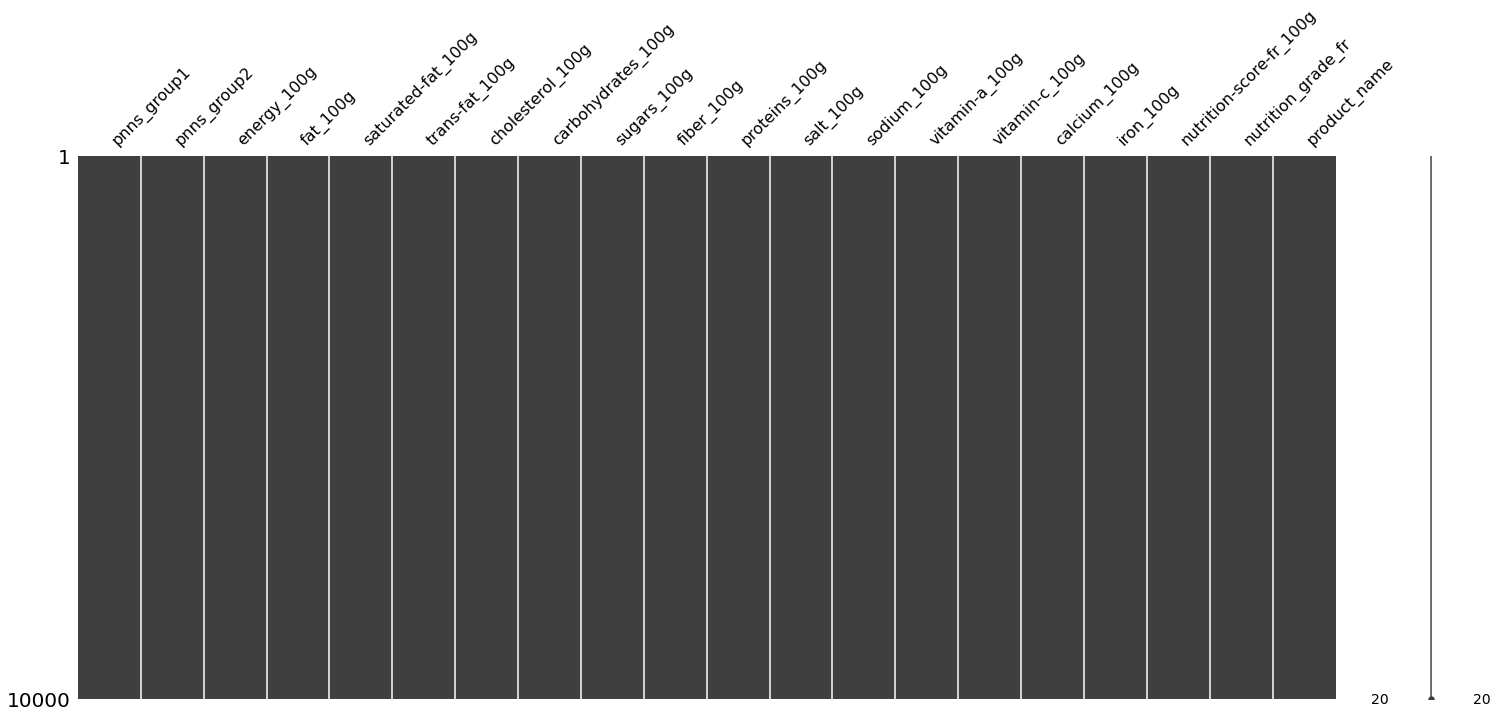

In [11]:
%matplotlib inline
msno.matrix(data)

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl</strong> : Plus de NaN, toutes les valeurs manquantes ont bien été imputées</p>

In [12]:
duplicate = data[data.duplicated()].sort_values('pnns_group1')
duplicate

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
9985,Beverages,Alcoholic beverages,100.0,0.00,0.00,0.0,0.000,3.53,0.00,2.40,2.35,0.28448,0.112000,0.001412,0.0056,0.047,0.000850,-3.0,a,Spring Mix
9545,Beverages,Sweetened beverages,165.0,0.00,0.00,0.0,0.000,9.40,9.10,0.04,0.00,0.00000,0.000000,0.000012,0.0260,0.004,0.000144,13.0,e,Pocket Tropical
8556,Beverages,Alcoholic beverages,105.0,0.00,0.00,0.0,0.000,6.67,1.67,4.20,1.67,0.76200,0.300000,0.000075,0.0100,0.033,0.000300,-3.0,a,Artichoke Hearts
7430,Beverages,Alcoholic beverages,155.0,0.00,0.00,0.0,0.000,3.70,1.23,1.20,2.47,0.37592,0.148000,0.000926,0.0015,0.099,0.000890,-1.0,a,Cut Leaf Spinach
3624,Beverages,Sweetened beverages,118.0,0.00,0.00,0.0,0.000,6.60,6.60,0.00,0.00,0.00000,0.000000,0.000012,0.0190,0.004,0.000144,9.0,d,Sprite
5446,Cereals and potatoes,Alcoholic beverages,280.0,0.00,0.00,0.0,0.000,12.22,4.44,2.20,2.22,0.07112,0.028000,0.000417,0.0040,0.022,0.000000,-4.0,a,Mixed Vegetables
5634,Cereals and potatoes,Alcoholic beverages,381.0,0.00,0.00,0.0,0.000,18.18,9.09,6.10,6.06,0.11430,0.045000,0.000364,0.0145,0.000,0.002180,-5.0,a,Tomato Paste
6503,Cereals and potatoes,Breakfast cereals,1611.0,0.00,0.00,0.0,0.000,84.62,23.08,0.00,7.69,0.58674,0.231000,0.000000,0.0000,0.000,0.000000,11.0,d,Rice Cakes
6528,Cereals and potatoes,Alcoholic beverages,356.0,1.15,0.00,0.0,0.000,13.85,0.77,4.60,4.62,0.93726,0.369000,0.000000,0.0000,0.031,0.001110,-2.0,a,Traditional Refried Beans
8305,Cereals and potatoes,Legumes,2485.0,50.00,7.81,0.0,0.000,25.00,9.38,6.20,21.88,1.11252,0.438000,0.000000,0.0000,0.062,0.002250,15.0,d,Creamy Peanut Butter


In [13]:
duplicate.shape

(65, 20)

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl</strong> : On supprime les quelques doublons pour n'avoir qu'un choix de product_name possible</p>

In [14]:
nutri_app = data.drop_duplicates()
nutri_app 

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
0,Sugary snacks,Chocolate products,2309.0,33.00,19.00,0.00,10.900,50.00,50.00,2.10,4.90,0.08000,0.031496,0.000075,0.0000,0.2680,0.002700,26.0,e,Extra Fondant
1,unknown,Alcoholic beverages,322.0,0.00,0.00,0.00,0.000,19.23,14.62,1.50,0.00,0.02032,0.008000,0.000000,0.0000,0.0000,0.000000,1.0,b,"Pride, Bartlett Pears In Heavy Syrup"
2,Fat and sauces,Alcoholic beverages,657.0,0.00,0.00,0.00,0.000,35.71,30.00,1.40,0.00,0.03556,0.014000,0.000000,0.0000,0.0000,0.000000,6.0,c,Jellied Cranberry Sauce
3,Fat and sauces,Alcoholic beverages,1109.0,20.59,8.82,0.00,0.029,17.65,11.76,0.00,5.88,0.56134,0.221000,0.000353,0.0000,0.0000,0.000000,15.0,d,"Brooks Street Bakery, Classic European Pastry ..."
4,unknown,unknown,2192.0,32.00,20.00,0.00,0.000,52.00,51.00,0.00,6.40,0.27000,0.106299,0.000527,0.0650,0.3300,0.005200,27.0,e,Sachets de 45 méga oeufs au chocolat au lait p...
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,unknown,unknown,288.0,1.40,0.90,0.10,0.000,11.20,11.20,1.30,2.70,0.10000,0.039370,0.000101,0.0143,0.1200,0.002100,1.0,b,Lait fermenté à boire LB6 nature sucré
9996,unknown,Alcoholic beverages,1322.0,14.04,3.51,3.51,0.000,43.86,8.77,1.80,5.26,2.04978,0.807000,0.000000,0.0000,0.0000,0.002530,13.0,d,Biscuits
9997,Fruits and vegetables,Vegetables,85.0,0.70,0.14,0.00,0.000,0.10,0.05,1.58,2.80,0.14500,0.057087,0.000000,0.0000,0.0174,0.000626,-8.0,a,Jeunes pousses d'épinard
9998,Milk and dairy products,Alcoholic beverages,272.0,2.94,1.76,0.00,0.012,7.06,5.29,0.60,2.94,0.37338,0.147000,0.000035,0.0035,0.0880,0.000210,2.0,b,All Natural Yogurt


## suppression des valeurs unknown de pnns_group1 pour la réalisation de l'appli

In [15]:
nutri_app = nutri_app[nutri_app.pnns_group1 != 'unknown']

In [16]:
nutri_app.head(5)

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
0,Sugary snacks,Chocolate products,2309.0,33.00,19.00,0.0,10.900,50.00,50.00,2.1,4.90,0.08000,0.031496,0.000075,0.0000,0.268,0.00270,26.0,e,Extra Fondant
2,Fat and sauces,Alcoholic beverages,657.0,0.00,0.00,0.0,0.000,35.71,30.00,1.4,0.00,0.03556,0.014000,0.000000,0.0000,0.000,0.00000,6.0,c,Jellied Cranberry Sauce
3,Fat and sauces,Alcoholic beverages,1109.0,20.59,8.82,0.0,0.029,17.65,11.76,0.0,5.88,0.56134,0.221000,0.000353,0.0000,0.000,0.00000,15.0,d,"Brooks Street Bakery, Classic European Pastry ..."
7,Sugary snacks,Biscuits and cakes,1703.0,18.52,1.85,0.0,0.056,55.56,38.89,1.9,5.56,0.46990,0.185000,0.000139,0.0022,0.019,0.00733,14.0,d,"Ready To Bake, Brownies Mix"
8,Sugary snacks,Chocolate products,1954.0,26.67,13.33,0.0,0.022,55.56,42.22,2.2,4.44,0.19812,0.078000,0.000000,0.0000,0.133,0.00080,21.0,e,"Pixies, Milk Chocolate"


In [17]:
nutri_app.shape

(6630, 20)

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl</strong> : On est passé d'un sous-échantillon de 10 000 données à 6630</p>

## analyse univariée

In [18]:
nutri_quali = nutri_app.select_dtypes(exclude=['float64'])

In [19]:
nutri_quanti = nutri_app.select_dtypes(include=['float64'])

### variables quali

In [20]:
nutri_quali.columns

Index(['pnns_group1', 'pnns_group2', 'nutrition_grade_fr', 'product_name'], dtype='object')

In [21]:
df_quali_col = nutri_quali['nutrition_grade_fr']

In [22]:
total = df_quali_col.value_counts().values.sum()

def fmt(x):
    return '{:.1f}%\n{:.0f}'.format(x, total*x/100)



In [23]:
import matplotlib.pyplot as plt

def plot_pie_chart(df_quali_col: pd.DataFrame) -> None:
    """
    Plots a pie chart of the value counts of the input dataframe.
    
    Parameters:
    df_quali_col (pd.DataFrame): Dataframe with the data to plot
    
    Returns:
    None
    """
    # Data to plot 
    colors = ['lightcoral', 'gold','red','lightskyblue','yellowgreen']
    
    # Plot
    plt.figure(figsize=(10,6))
    plt.pie(df_quali_col.value_counts().values, labels=df_quali_col.value_counts().index, colors=colors,
            autopct='%1.1f%%', shadow=True, startangle=140)
    
    plt.axis('equal')
    plt.show()

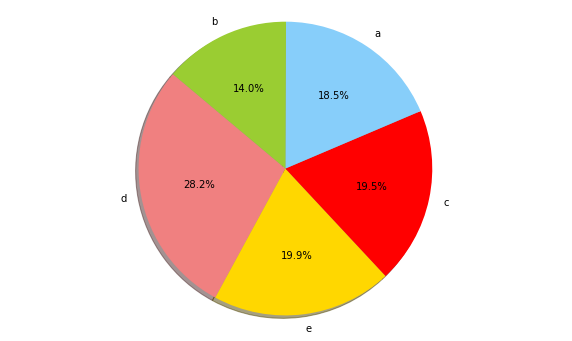

In [24]:
plot_pie_chart(df_quali_col)

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> nb de product_name classé dans les variables quali a,b,c,d,e a peu près homogène<br>
plus de nutriscore c et d que a et b, avec majorité de d</p>

<AxesSubplot:>

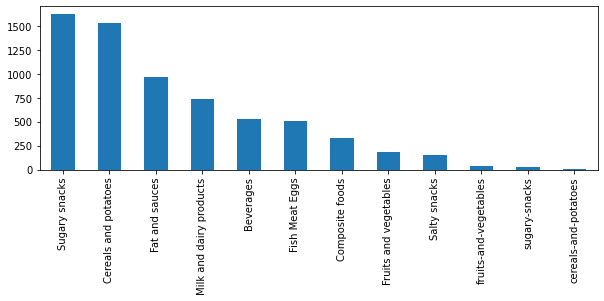

In [25]:
nutri_quali['pnns_group1'].value_counts().plot(kind='bar', figsize=(10,3))

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> On a supprimé les valeurs "unknown".<br> Cela confirme le résultat selon lequel la majorité des produits présentent un mauvais Nutri-Score et une mauvaise qualité nutritionnelle.</p>

In [26]:
nutri_quali['pnns_group1'].unique()

array(['Sugary snacks', 'Fat and sauces', 'Fish Meat Eggs',
       'Cereals and potatoes', 'Milk and dairy products', 'Beverages',
       'Composite foods', 'Fruits and vegetables', 'sugary-snacks',
       'Salty snacks', 'fruits-and-vegetables', 'cereals-and-potatoes'],
      dtype=object)

<AxesSubplot:>

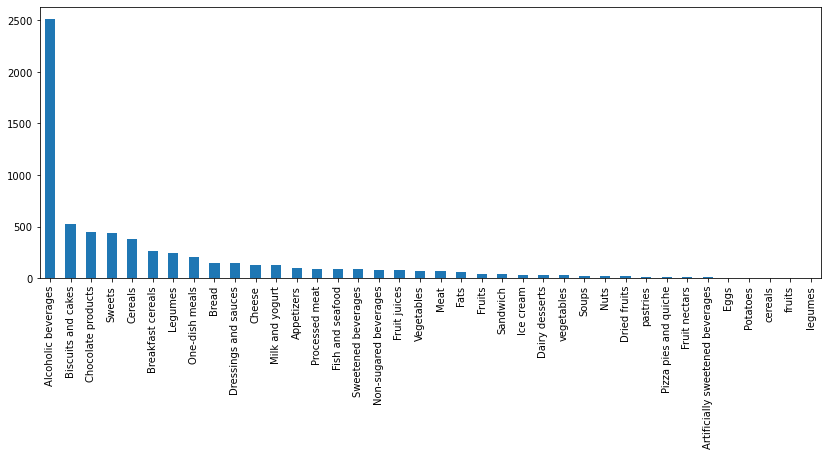

In [27]:
nutri_quali['pnns_group2'].value_counts().plot(kind='bar', figsize=(14,5))

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> top 3 représentés dans pnns group 2 "alcoholic beverage, tripe dishes et chocolate products. Supprimer la colonne unknown du "pnns_group_1" a supprimé toutes les valeurs "unknown" de pnns_group_2
</p>

In [28]:
nutri_quali['pnns_group2'].unique()

array(['Chocolate products', 'Alcoholic beverages', 'Biscuits and cakes',
       'Fish and seafood', 'Fats', 'Milk and yogurt', 'Sweets',
       'Breakfast cereals', 'Bread', 'Legumes', 'Dressings and sauces',
       'Ice cream', 'Cereals', 'Meat', 'Sweetened beverages',
       'One-dish meals', 'Non-sugared beverages', 'Fruits', 'pastries',
       'Vegetables', 'Appetizers', 'Fruit nectars', 'vegetables',
       'Cheese', 'Sandwich', 'Soups', 'Artificially sweetened beverages',
       'Potatoes', 'Fruit juices', 'Processed meat', 'Nuts',
       'Dried fruits', 'cereals', 'Eggs', 'Dairy desserts',
       'Pizza pies and quiche', 'fruits', 'legumes'], dtype=object)

In [29]:
nutri_quali['product_name'].count()

6630

In [30]:
nutri_quali.loc[nutri_quali['product_name'].duplicated()==True].count()

pnns_group1           370
pnns_group2           370
nutrition_grade_fr    370
product_name          370
dtype: int64

In [31]:
nutri_quali.loc[nutri_quali['product_name'].duplicated()==True].sort_values(by=['product_name']).head(15)

,pnns_group1,pnns_group2,nutrition_grade_fr,product_name
2749,Milk and dairy products,Alcoholic beverages,a,1% Low Fat Milk
4690,Milk and dairy products,Alcoholic beverages,a,1% Low Fat Milk
5917,Beverages,Alcoholic beverages,b,1% Low Fat Milk
6701,Milk and dairy products,Alcoholic beverages,a,1% Lowfat Milk
6681,Beverages,Fruit juices,c,100% Pur Jus Multifruits
3947,Milk and dairy products,Milk and yogurt,b,2% Reduced Fat Milk
6097,Fat and sauces,Alcoholic beverages,c,Alfredo Sauce
8351,Fat and sauces,Alcoholic beverages,c,Alfredo Sauce
3388,Cereals and potatoes,Legumes,c,Almonds
6161,Cereals and potatoes,Legumes,c,Almonds


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl : </strong>L'inclusion de produits laitiers dans la catégorie "boisson alcoolisée" est une anomalie non prévue.</p>

In [32]:
nutri_quali['product_name'].nunique()

6260

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> 632 product name en double</p>

### variables quanti, boxplot et distribution des nutriments

In [33]:
nutri_quanti.columns

Index(['energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'calcium_100g', 'iron_100g', 'nutrition-score-fr_100g'], dtype='object')

In [34]:
nutri_quanti.describe()

,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g
count,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000,6630.000000
mean,1164.951652,12.516476,4.859901,0.067029,0.090008,35.075206,17.977074,2.575482,6.956714,1.045587,0.411648,0.000098,0.008521,0.078336,0.003060,8.985068
std,779.104433,16.361616,7.883236,0.722049,0.904308,29.264674,21.778143,4.456194,7.100317,3.148052,1.239389,0.000339,0.037161,0.276244,0.059587,9.424402
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,-13.000000
25%,423.000000,0.610000,0.000000,0.000000,0.000000,7.960000,1.812500,0.000000,1.670000,0.093980,0.037000,0.000000,0.000000,0.000000,0.000000,1.000000
50%,1116.500000,5.000000,1.335000,0.000000,0.000000,26.095000,6.670000,1.200000,5.000000,0.508000,0.200000,0.000000,0.000000,0.035700,0.001160,10.000000
75%,1773.000000,19.975000,7.000000,0.000000,0.012500,62.000000,30.000000,3.400000,9.520000,1.198880,0.472000,0.000088,0.004200,0.105000,0.002510,16.000000
max,3740.000000,100.000000,92.000000,38.460000,10.900000,100.000000,100.000000,100.000000,64.290000,73.660000,29.000000,0.015000,1.428600,18.919000,2.800000,40.000000


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">nutrition-score-fr_100g le score va de 40 à -13 pour ce dataset</p>

In [35]:
nutri_app

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
0,Sugary snacks,Chocolate products,2309.0,33.000,19.00,0.0,10.9000,50.00,50.00,2.10,4.90,0.08000,0.031496,0.000075,0.0000,0.26800,0.002700,26.0,e,Extra Fondant
2,Fat and sauces,Alcoholic beverages,657.0,0.000,0.00,0.0,0.0000,35.71,30.00,1.40,0.00,0.03556,0.014000,0.000000,0.0000,0.00000,0.000000,6.0,c,Jellied Cranberry Sauce
3,Fat and sauces,Alcoholic beverages,1109.0,20.590,8.82,0.0,0.0290,17.65,11.76,0.00,5.88,0.56134,0.221000,0.000353,0.0000,0.00000,0.000000,15.0,d,"Brooks Street Bakery, Classic European Pastry ..."
7,Sugary snacks,Biscuits and cakes,1703.0,18.520,1.85,0.0,0.0560,55.56,38.89,1.90,5.56,0.46990,0.185000,0.000139,0.0022,0.01900,0.007330,14.0,d,"Ready To Bake, Brownies Mix"
8,Sugary snacks,Chocolate products,1954.0,26.670,13.33,0.0,0.0220,55.56,42.22,2.20,4.44,0.19812,0.078000,0.000000,0.0000,0.13300,0.000800,21.0,e,"Pixies, Milk Chocolate"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9990,Fat and sauces,Dressings and sauces,160.0,3.000,0.10,0.0,0.0000,6.20,5.60,2.00,1.70,0.50000,0.196850,0.000180,0.0072,0.01600,0.001150,0.0,b,Chunky Tomato Sauce
9991,Milk and dairy products,Ice cream,1149.0,14.900,10.00,0.0,0.0118,31.80,24.90,0.30,3.10,0.19000,0.074803,0.000210,0.0000,0.37700,0.000000,17.0,d,Mars Ice Cream
9993,Beverages,Non-sugared beverages,199.0,0.625,0.00,0.0,0.0000,8.75,7.92,0.00,2.08,0.00000,0.000000,0.000000,0.0000,0.00833,0.000300,0.0,b,Honey Soy Drink
9997,Fruits and vegetables,Vegetables,85.0,0.700,0.14,0.0,0.0000,0.10,0.05,1.58,2.80,0.14500,0.057087,0.000000,0.0000,0.01740,0.000626,-8.0,a,Jeunes pousses d'épinard


In [36]:
cols_num = nutri_app[['energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'calcium_100g', 'iron_100g']].columns



In [37]:
nutri_app[cols_num]

,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g
0,2309.0,33.000,19.00,0.0,10.9000,50.00,50.00,2.10,4.90,0.08000,0.031496,0.000075,0.0000,0.26800,0.002700
2,657.0,0.000,0.00,0.0,0.0000,35.71,30.00,1.40,0.00,0.03556,0.014000,0.000000,0.0000,0.00000,0.000000
3,1109.0,20.590,8.82,0.0,0.0290,17.65,11.76,0.00,5.88,0.56134,0.221000,0.000353,0.0000,0.00000,0.000000
7,1703.0,18.520,1.85,0.0,0.0560,55.56,38.89,1.90,5.56,0.46990,0.185000,0.000139,0.0022,0.01900,0.007330
8,1954.0,26.670,13.33,0.0,0.0220,55.56,42.22,2.20,4.44,0.19812,0.078000,0.000000,0.0000,0.13300,0.000800
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9990,160.0,3.000,0.10,0.0,0.0000,6.20,5.60,2.00,1.70,0.50000,0.196850,0.000180,0.0072,0.01600,0.001150
9991,1149.0,14.900,10.00,0.0,0.0118,31.80,24.90,0.30,3.10,0.19000,0.074803,0.000210,0.0000,0.37700,0.000000
9993,199.0,0.625,0.00,0.0,0.0000,8.75,7.92,0.00,2.08,0.00000,0.000000,0.000000,0.0000,0.00833,0.000300
9997,85.0,0.700,0.14,0.0,0.0000,0.10,0.05,1.58,2.80,0.14500,0.057087,0.000000,0.0000,0.01740,0.000626


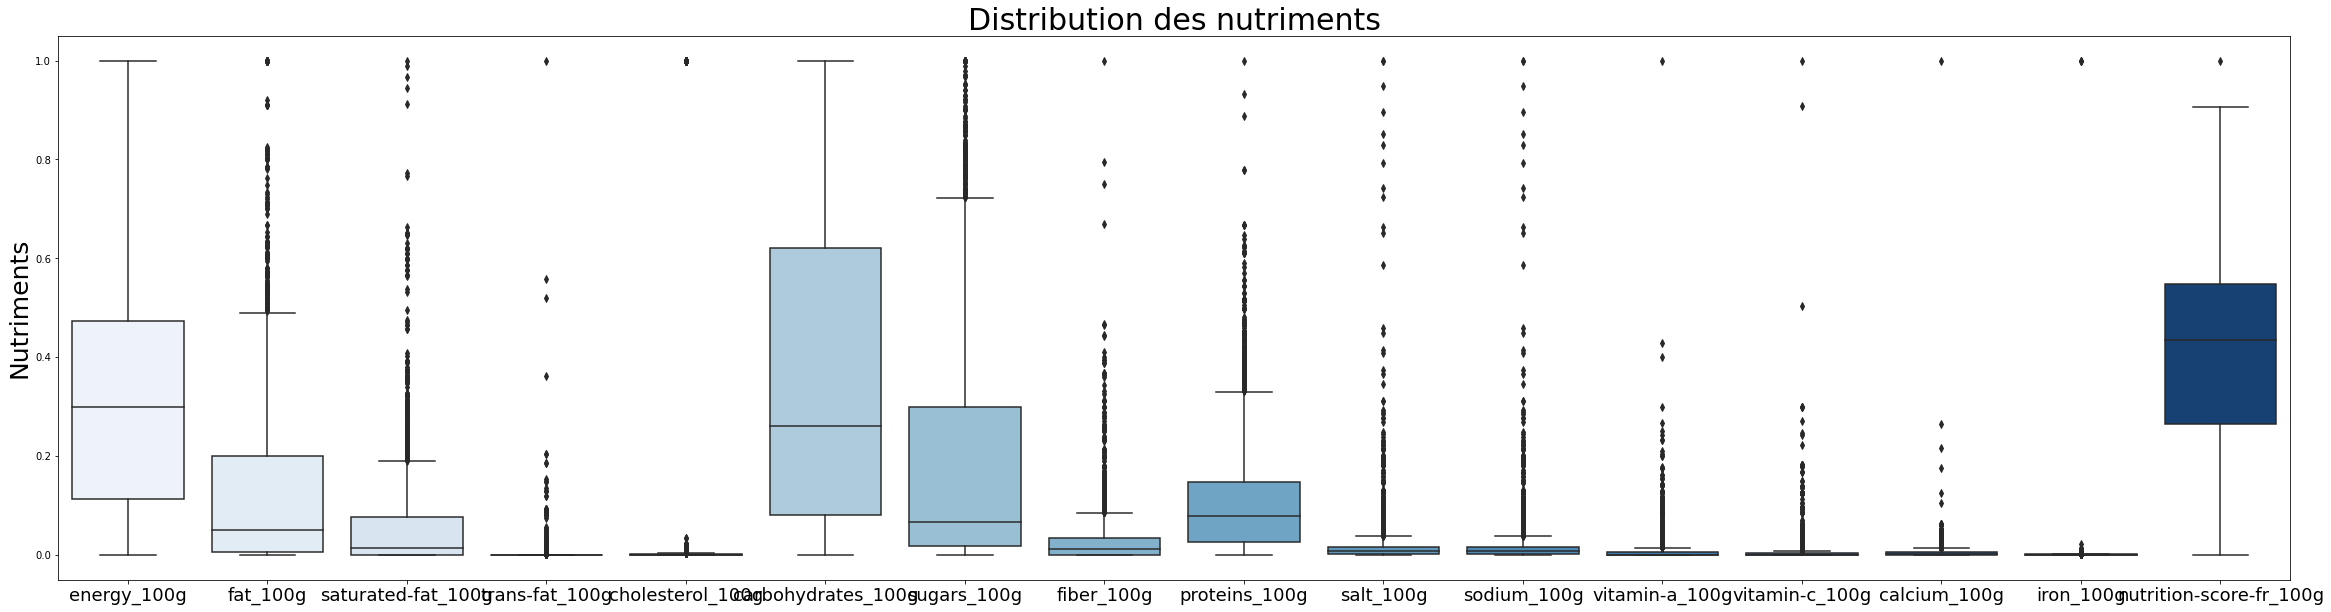

In [38]:
import seaborn as sb
import matplotlib.pyplot as plt

#normalize the data
data_norm = ((nutri_quanti - nutri_quanti.min()) / (nutri_quanti.max() - nutri_quanti.min()))

#plot the data
plt.figure(figsize=(40, 10)) 
ax = sb.boxplot(data = data_norm.loc[:, data_norm.columns], orient="v", palette="Blues")
plt.title("Distribution des nutriments", fontsize=30)
#change size of text on x-axis
ax.tick_params(axis='x', labelsize=18)
plt.ylabel("Nutriments", fontsize=25)
plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> Ce graphique montre la distribution des quantités de nutriments normalisés dans le jeu de données. <br>Le diagramme en boîte montre la gamme de valeurs pour chaque nutriment, le milieu de la boîte représentant la valeur médiane. Les moustaches représentent les valeurs minimales et maximales, tandis que les valeurs aberrantes représentent des valeurs significativement plus élevées ou plus faibles que le reste des données.</p>

In [39]:
import matplotlib.pyplot as plt

def plot_nutri_app_history(figsize=(20,20)):
    """Plots the history of the nutri_app data
    
    Parameters:
    -----------
    figsize : tuple
        The size of the figure to be plotted. Default is (20, 20)
    """
    nutri_app.hist(figsize=figsize)
    plt.show()

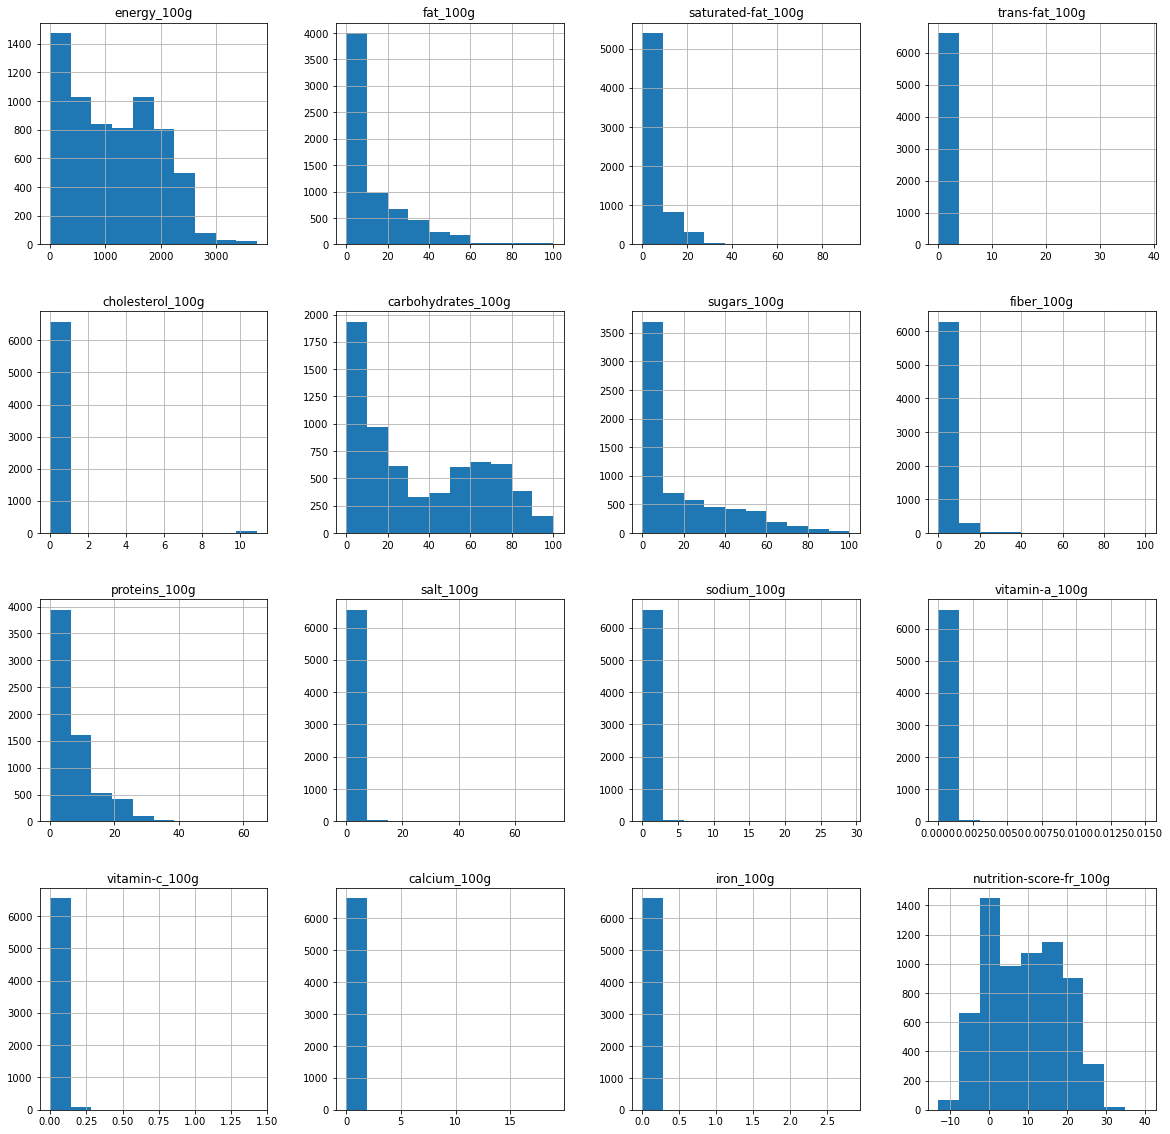

In [40]:
plot_nutri_app_history()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> Les histogrammes montrent la distribution des valeurs pour chaque colonne du dataframe nutri_app.
    ccl en abs la valeur prise, en ordonnée la quantite
        <br/> valeur tres faible pour iron et densité concentrée, alors qu'energie sucre fat, prot valeur plus etalees
        </p>

## analyse bivariée

<div style="background-color:orange; color:dark;"><strong>Objectifs:</strong><br>
L'objectif est de comprendre comment les variables quantitatives sélectionnées décrivent le nutriscore</div>

### scatter plots (nutriments vs nutrigrad), boîte à moustache (catégorie pnns group1 vs nutriscore):

In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
  
sns.set(style ="darkgrid")
  
dataset = nutri_app 

In [42]:
nutri_app.head(2)

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
0,Sugary snacks,Chocolate products,2309.0,33.0,19.0,0.0,10.9,50.00,50.0,2.1,4.9,0.08000,0.031496,0.000075,0.0,0.268,0.0027,26.0,e,Extra Fondant
2,Fat and sauces,Alcoholic beverages,657.0,0.0,0.0,0.0,0.0,35.71,30.0,1.4,0.0,0.03556,0.014000,0.000000,0.0,0.000,0.0000,6.0,c,Jellied Cranberry Sauce


In [43]:
nutri_app.columns

Index(['pnns_group1', 'pnns_group2', 'energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'calcium_100g', 'iron_100g', 'nutrition-score-fr_100g', 'nutrition_grade_fr', 'product_name'], dtype='object')

In [44]:
data_barplot = nutri_app.loc[:, nutri_app.columns.difference(['pnns_group2', 'energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'calcium_100g', 'iron_100g', 'product_name'])]

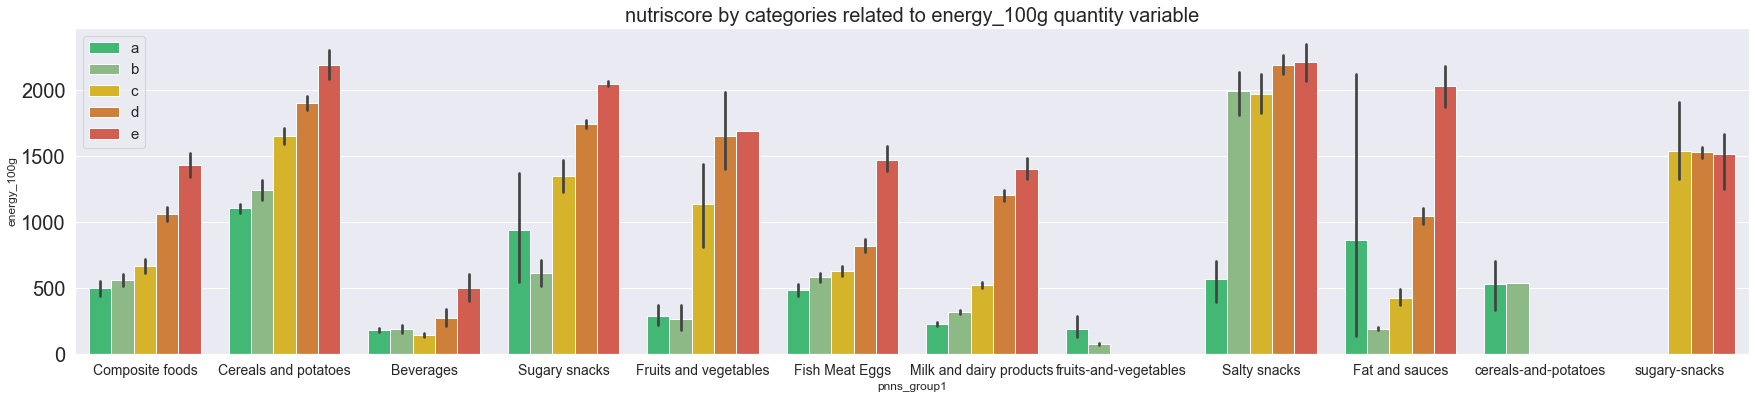

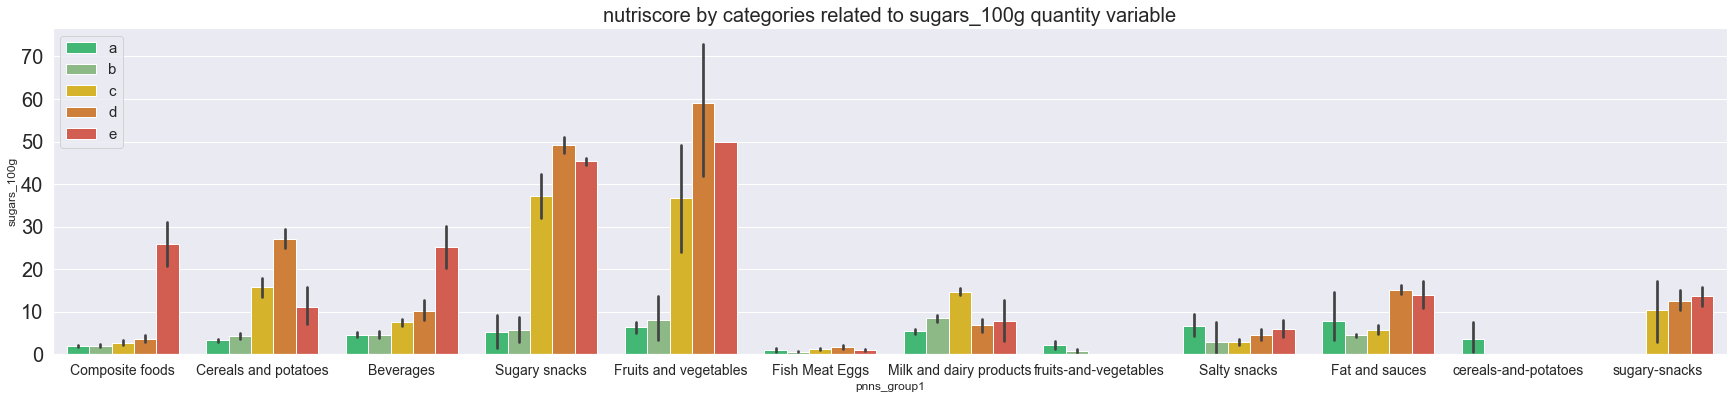

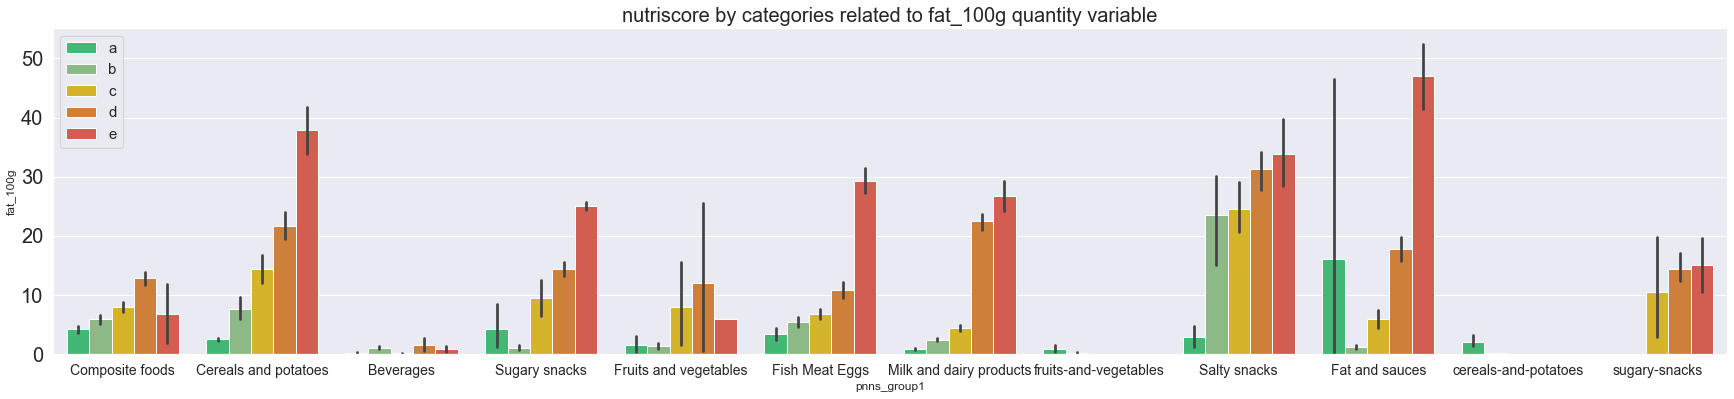

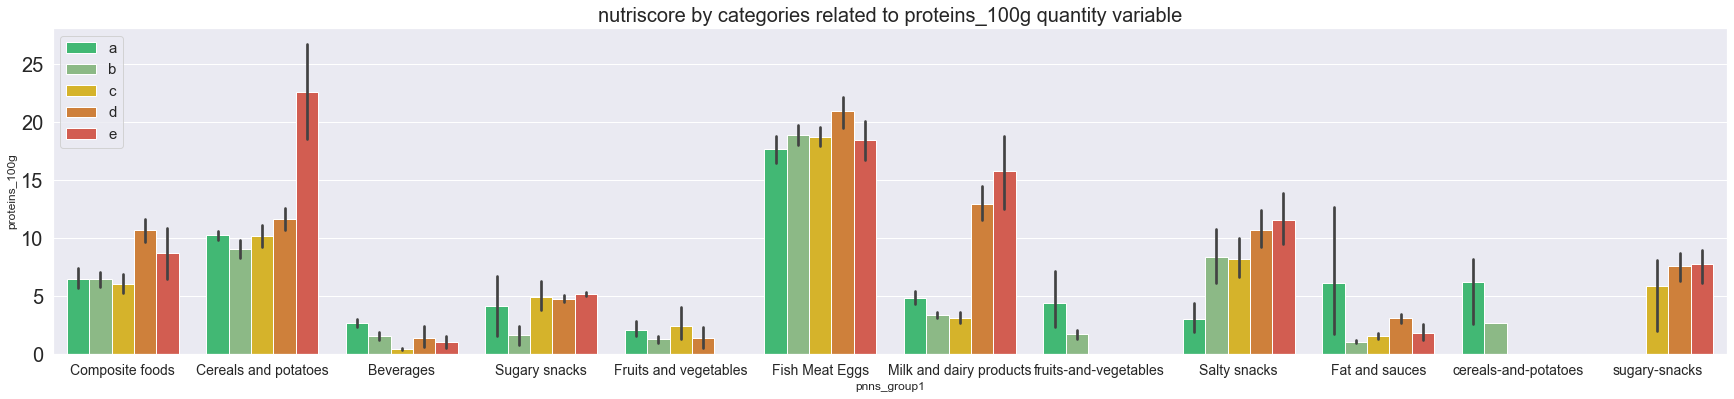

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt 

df = nutri_app.sort_values(by='nutrition_grade_fr') #ascending=True by default
palette = ['#2ECC71', '#85C17E', '#F1C40F', '#E67E22', '#E74C3C']
for elem in ['energy_100g', 'sugars_100g','fat_100g','proteins_100g']:
#Create barplot
    fig, ax = plt.subplots(figsize=(30,6))
    sns.barplot(x="pnns_group1", y=elem, hue="nutrition_grade_fr", data=df, palette=palette)

#Add title
    ax.set_title(f"nutriscore by categories related to {elem} quantity variable", fontsize=20)
    plt.legend(fontsize=15, loc='upper left')
    plt.yticks(fontsize=20)
    plt.xticks(fontsize=14)
    
#Show plot
plt.show();

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl : </strong>barplots pour visualiser la distribution du nutriscore pour chaque catégorie dans "pnns_group1" par rapport aux variables "energy_100g", "sugars_100g", "fat_100g" et "proteins_100g". Il utilise la bibliothèque "seaborn" pour créer le graphique à barres et la bibliothèque "matplotlib" pour personnaliser le graphique.<br> 
    Il trie le dataframe "nutri_app" par la colonne "nutrition_grade_fr" et crée une palette de couleurs à utiliser pour les différentes catégories de nutriscore. <br> "pnns_group1" sur l'axe des x, la valeur de la variable sur l'axe des y et le nutriscore sur le teinte. <br><br>• Une quantité trop élevée semble être corrélée à un  mauvais nutriscore.</p>

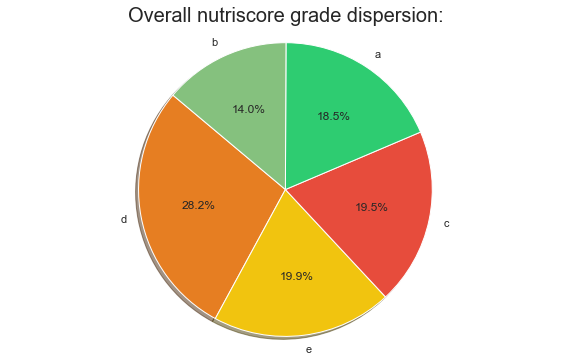

In [46]:
import matplotlib.pyplot as plt

# Data to plot 
colors = ['#E67E22', '#F1C40F','#E74C3C','#2ECC71','#85C17E']

# Plot
plt.figure(figsize=(10,6))
plt.pie(df_quali_col.value_counts().values, labels=df_quali_col.value_counts().index, colors=colors,
        autopct='%1.1f%%', shadow=True, startangle=140)

plt.axis('equal')
plt.title('Overall nutriscore grade dispersion:', fontsize=20)
plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl</strong> : Une majorité de nutri score C, D et E qui représentent à eux seul 68,9% du total</p>

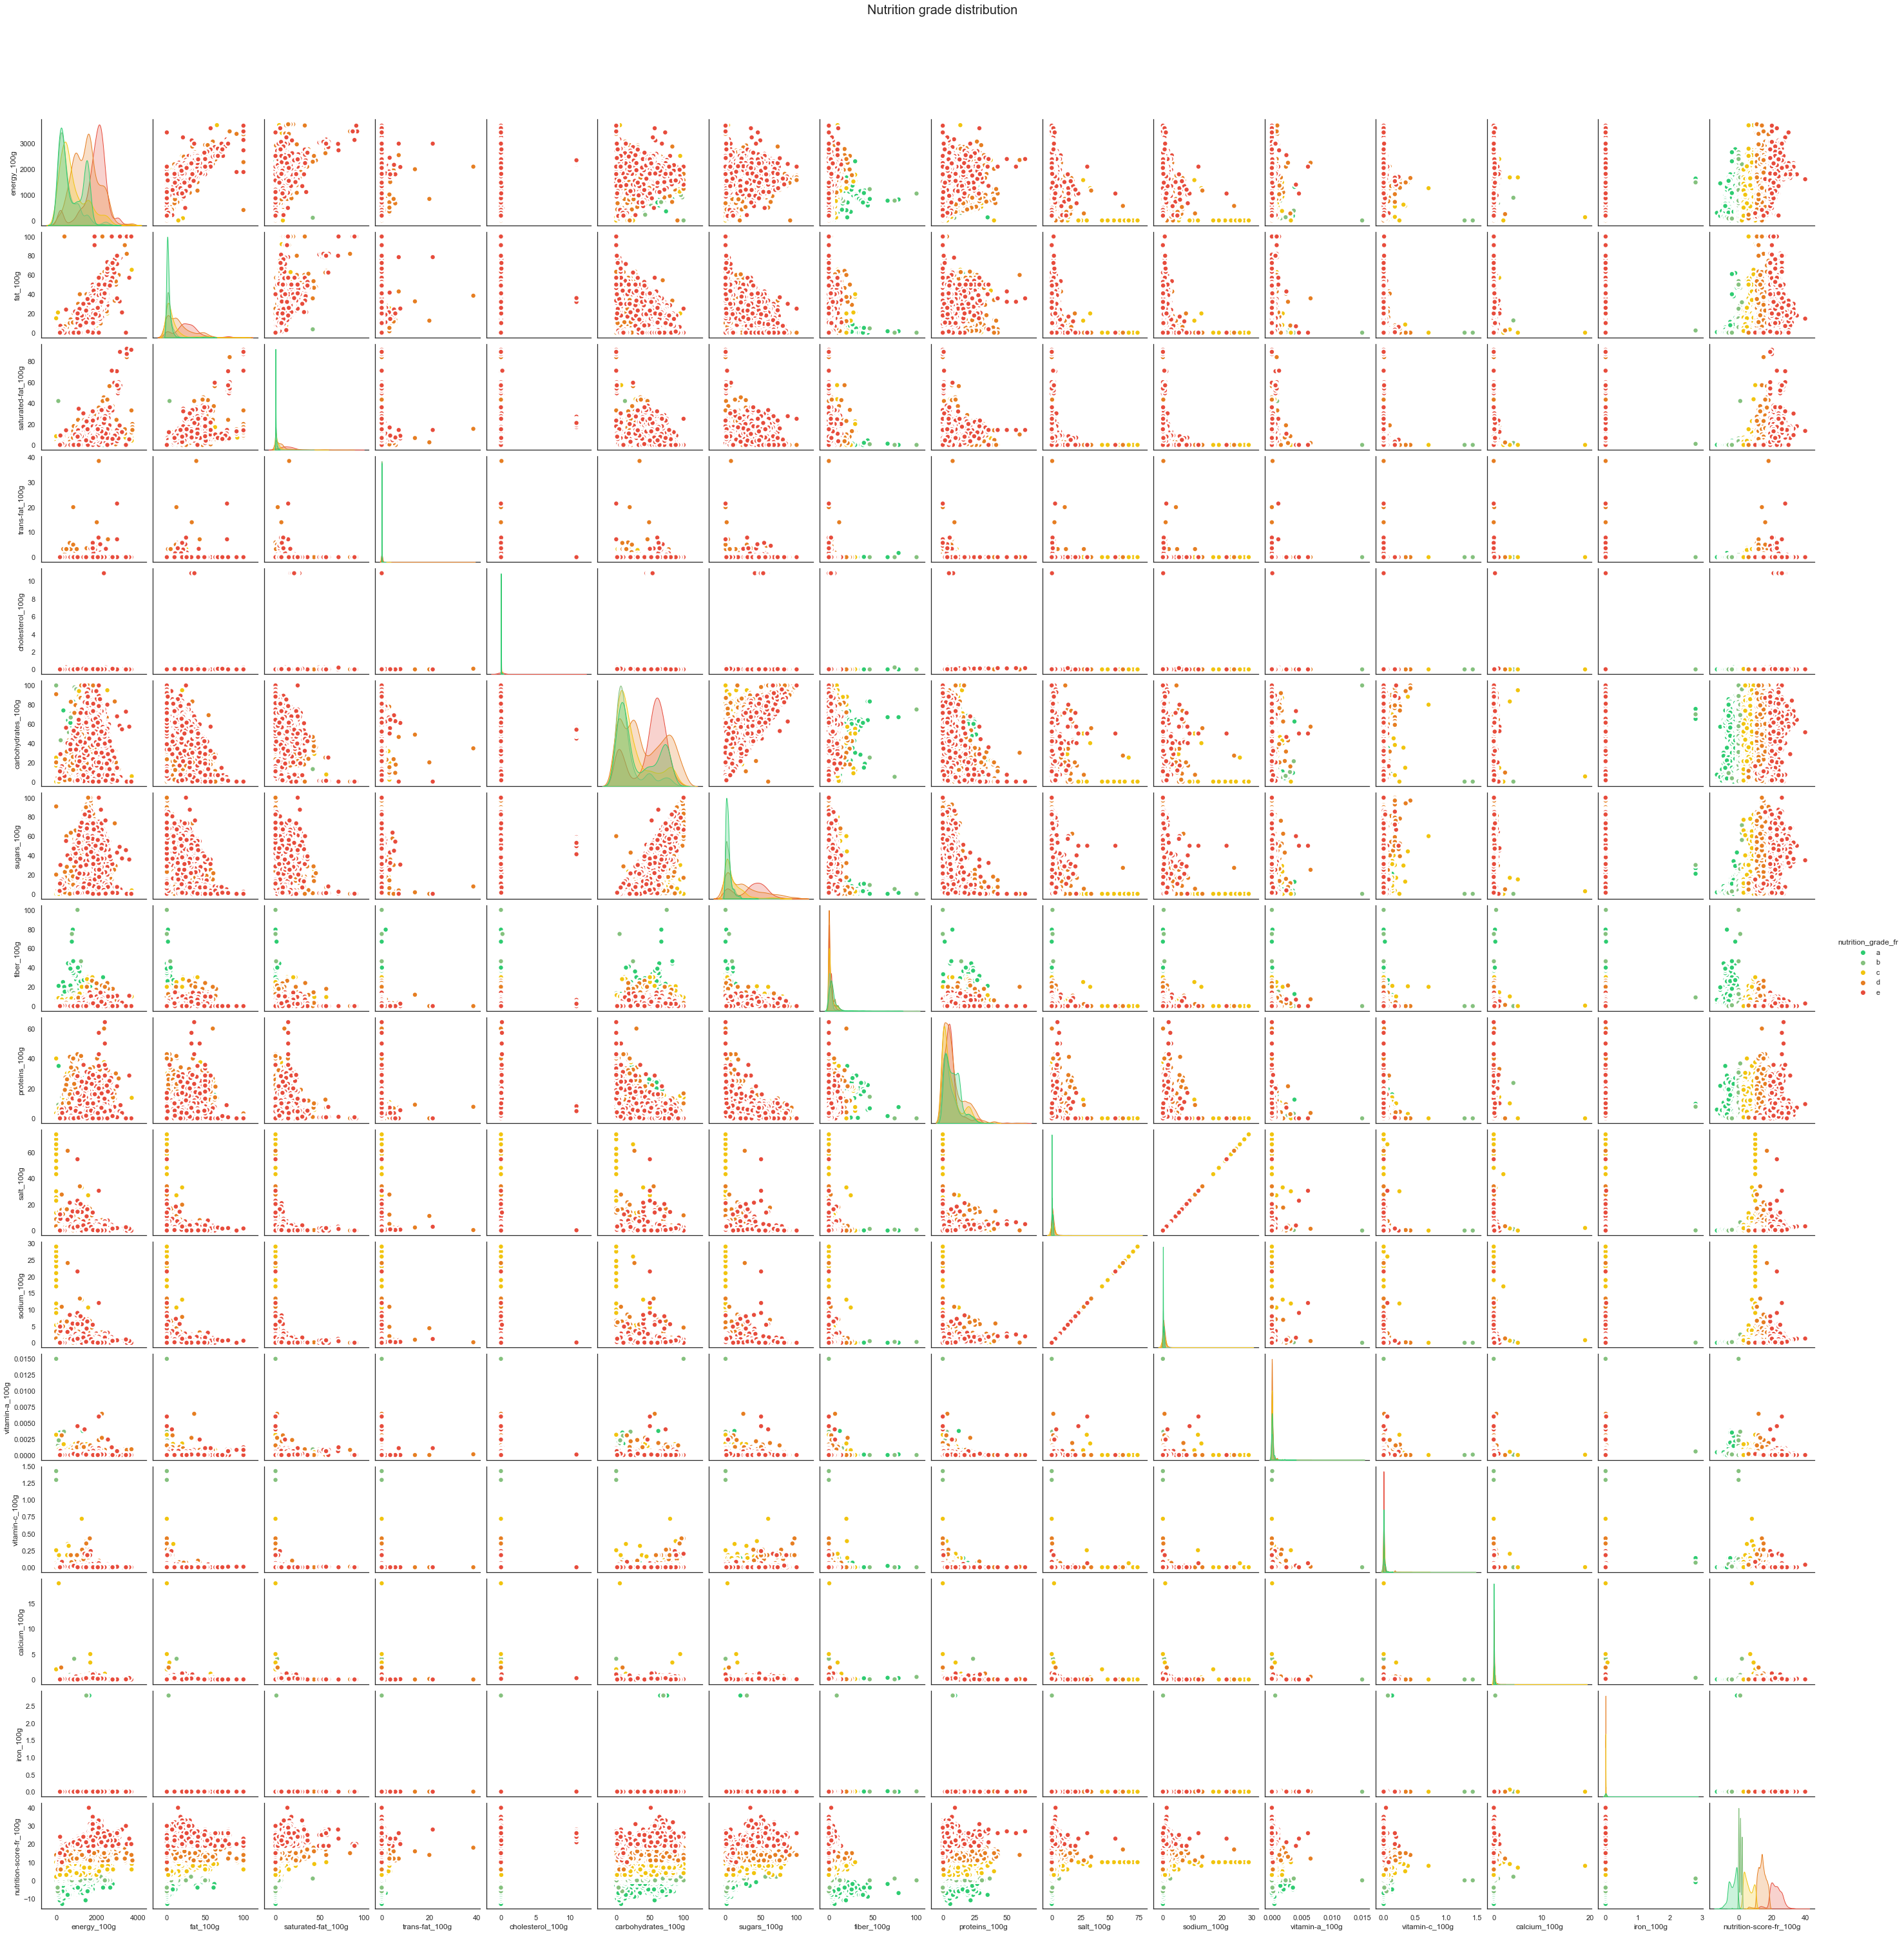

In [47]:
sns.set_style("white")
sns.pairplot(nutri_app.sort_values(by='nutrition_grade_fr'), kind='scatter', hue='nutrition_grade_fr', plot_kws=dict(s=80, edgecolor="white",
                                                        linewidth=2.5), palette=palette)

# Add title
plt.suptitle("Nutrition grade distribution", fontsize=20, y=1.05)

# Show plot
plt.show()

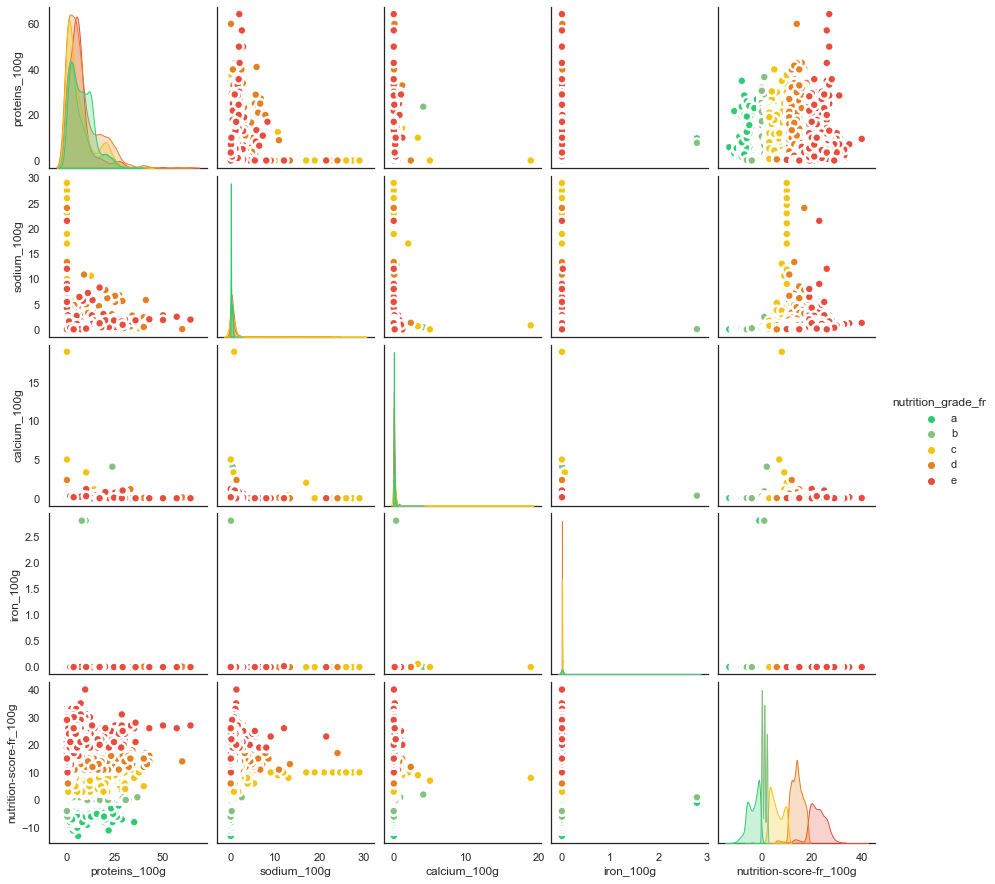

In [48]:
sns.set_style("white")

sns.pairplot(nutri_app.sort_values(by='nutrition_grade_fr').iloc[:,[10,12,15,16,17,18]], kind='scatter', hue='nutrition_grade_fr', plot_kws=dict(s=80, edgecolor="white",
                                                        linewidth=2.5), palette=palette)
plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl</strong> : correlation difficile a voir entre les différents groupes de  valeurs quantitatives<br>
- nutrison score et grade negativemeent corrélés, on voit que de 0 à -15 les valeurs du nutriscore sont des "a"</p>

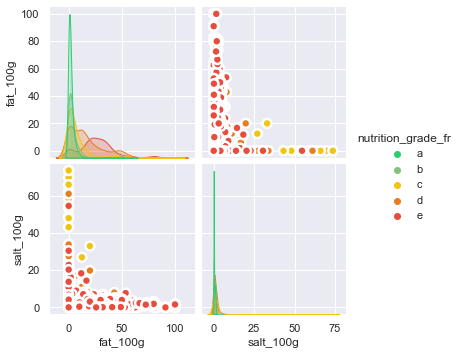

In [49]:
sns.set_style("white")
sns.set(rc = {'figure.figsize':(50,10)})
sns.pairplot(nutri_app.sort_values(by='nutrition_grade_fr')[["fat_100g","salt_100g","nutrition_grade_fr"]], kind='scatter', hue='nutrition_grade_fr', plot_kws=dict(s=80, edgecolor="white",
                                                        linewidth=2.5), palette=palette)
plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl</strong> le sel et le fat semblent impacter négativement le nutriscore</p>

/Users/laureagrech/opt/anaconda3/lib/python3.9/site-packages/pandas/core/frame.py:3678: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self[col] = igetitem(value, i)


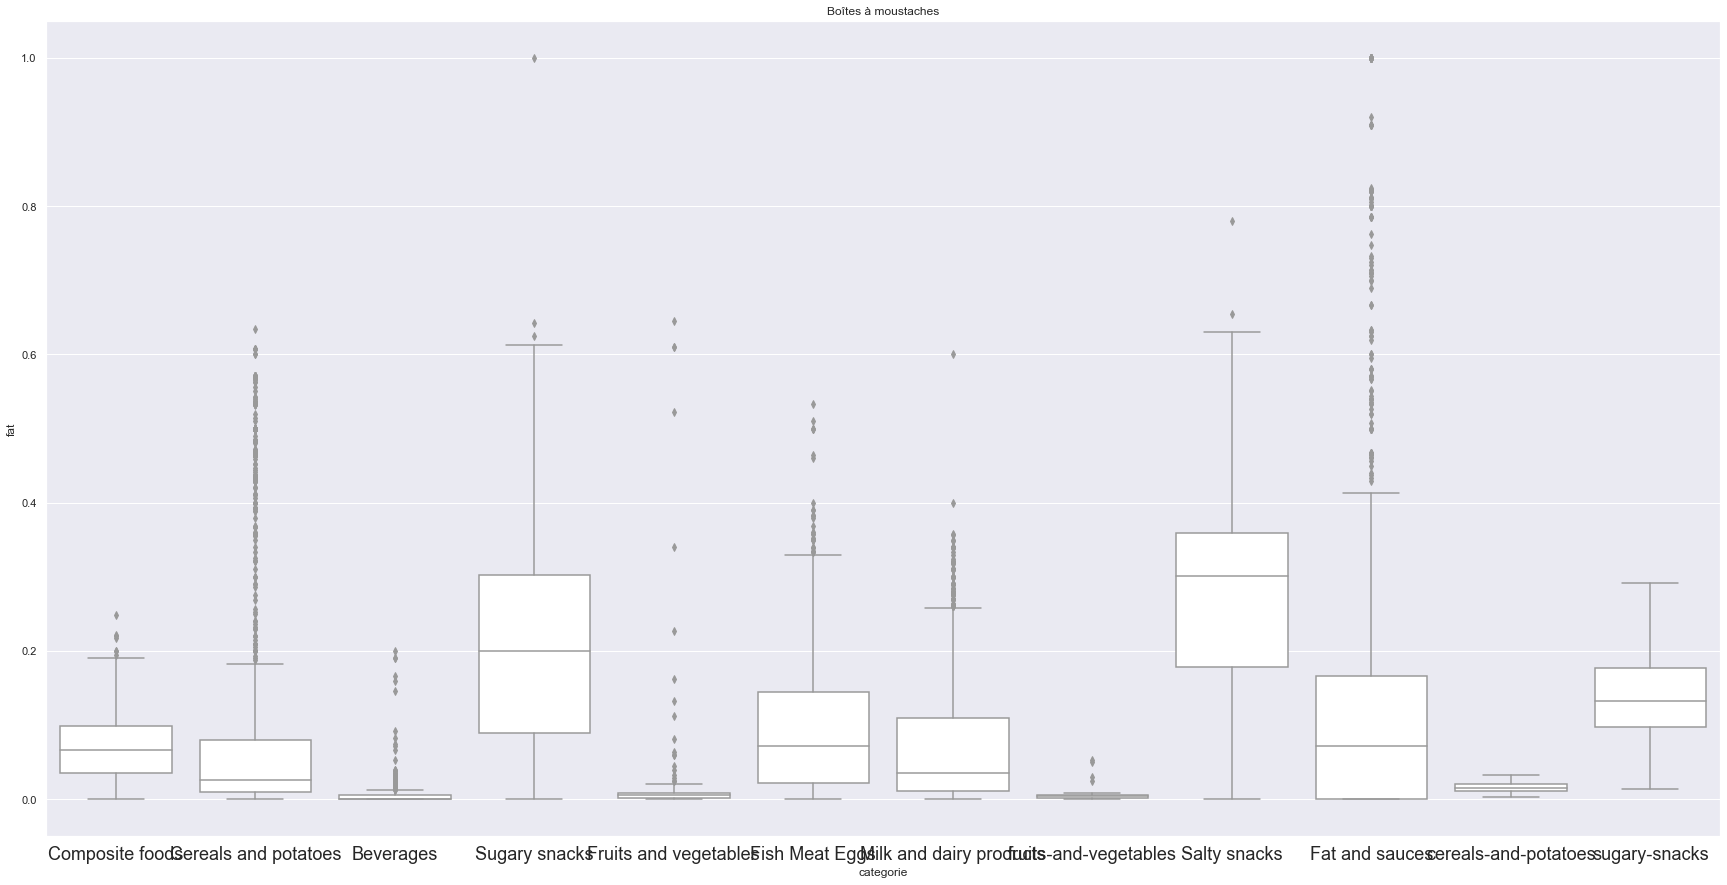

In [50]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()
nutri_app[['fat_100g']] = scaler.fit_transform(nutri_app[['fat_100g']])
fig, ax = plt.subplots(figsize=(30, 15))
ax = sns.boxplot(x="pnns_group1", y="fat_100g", data=nutri_app.sort_values(by='nutrition_grade_fr'), color='white')
ax.tick_params(axis='x', labelsize=18)
plt.xlabel('categorie')
plt.ylabel('fat')
plt.title('Boîtes à moustaches')
plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> Un boxplot normal serait centré dans le milieu de la boîte et aurait des moustaches qui sont égales de longueur et ne vont pas trop loin.<br> Si les moustaches sont plus longues, cela peut indiquer que la distribution n'est pas normale.<br> La distribution selon l'étude des boxplots ne semble donc pas normale</p>

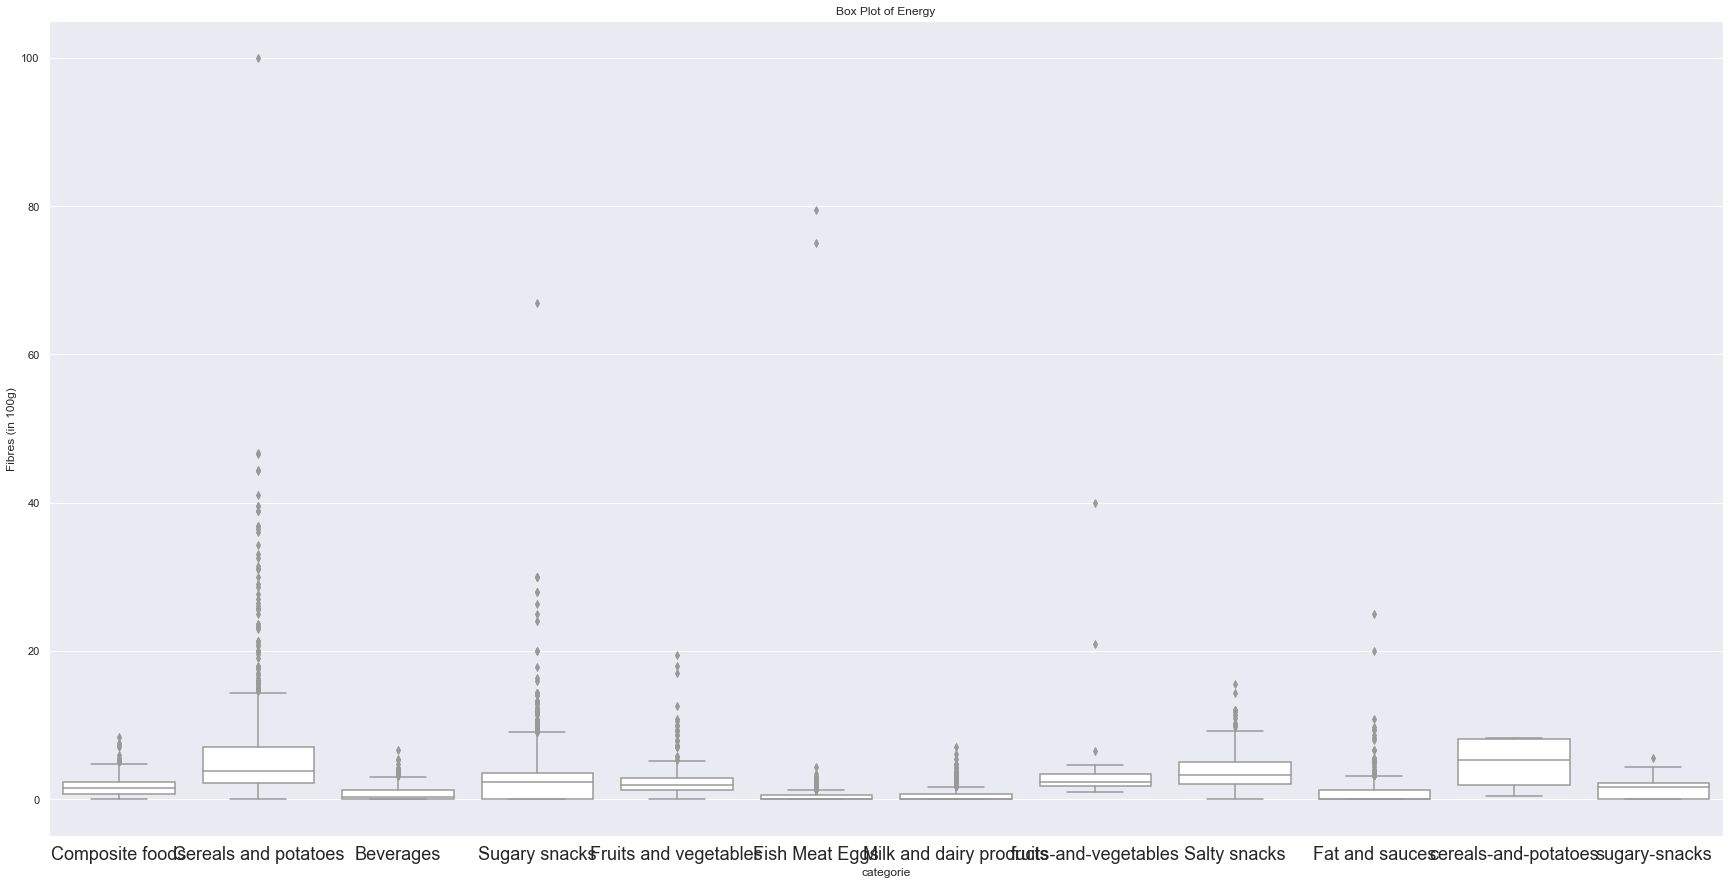

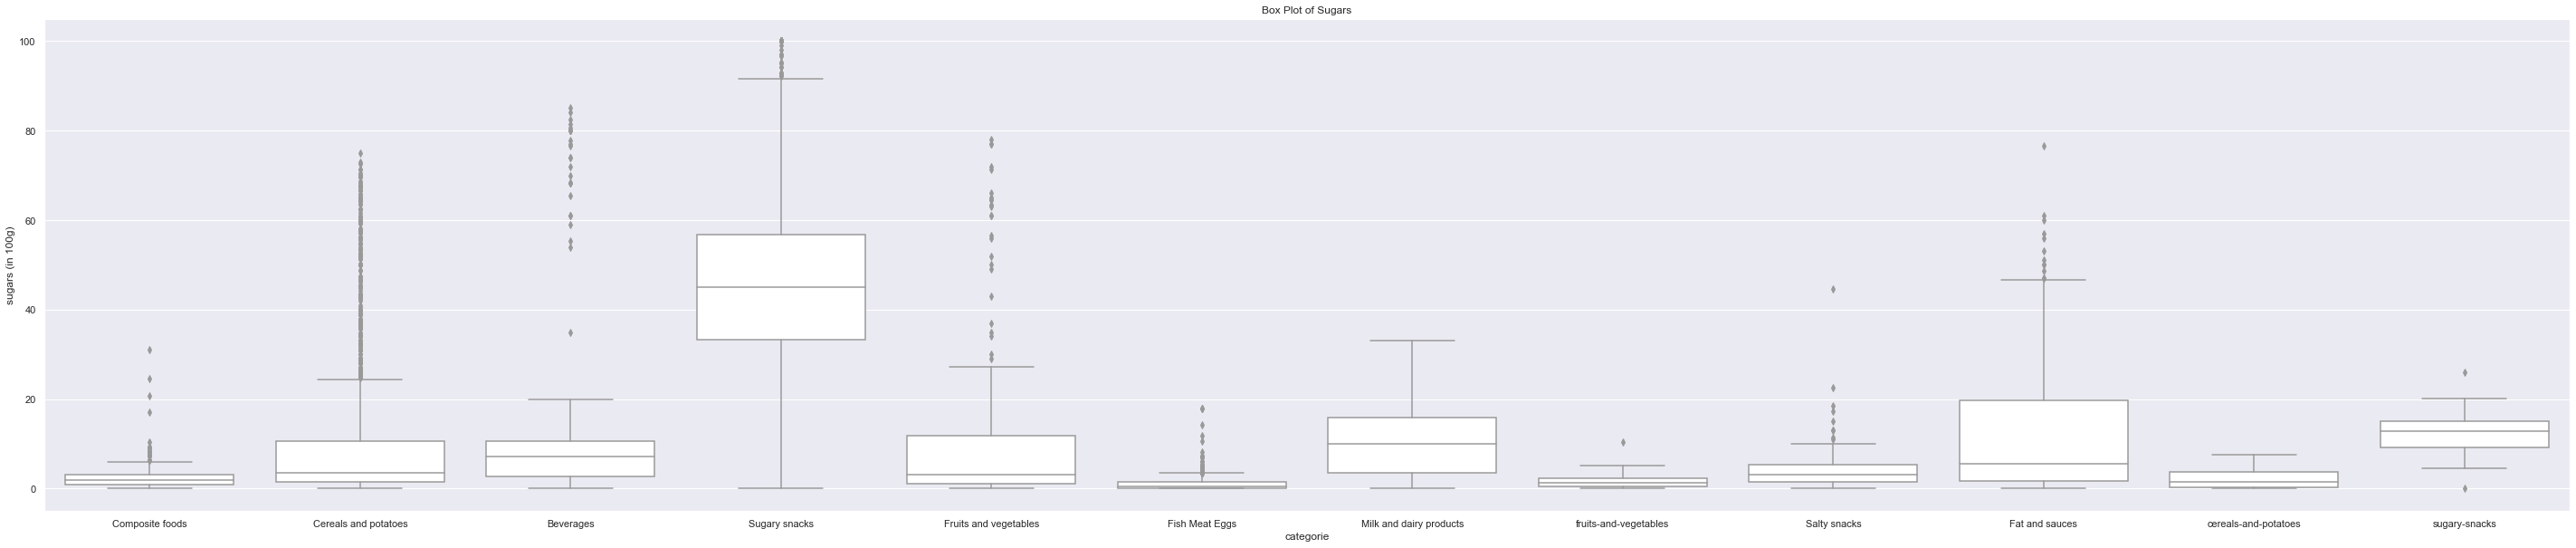

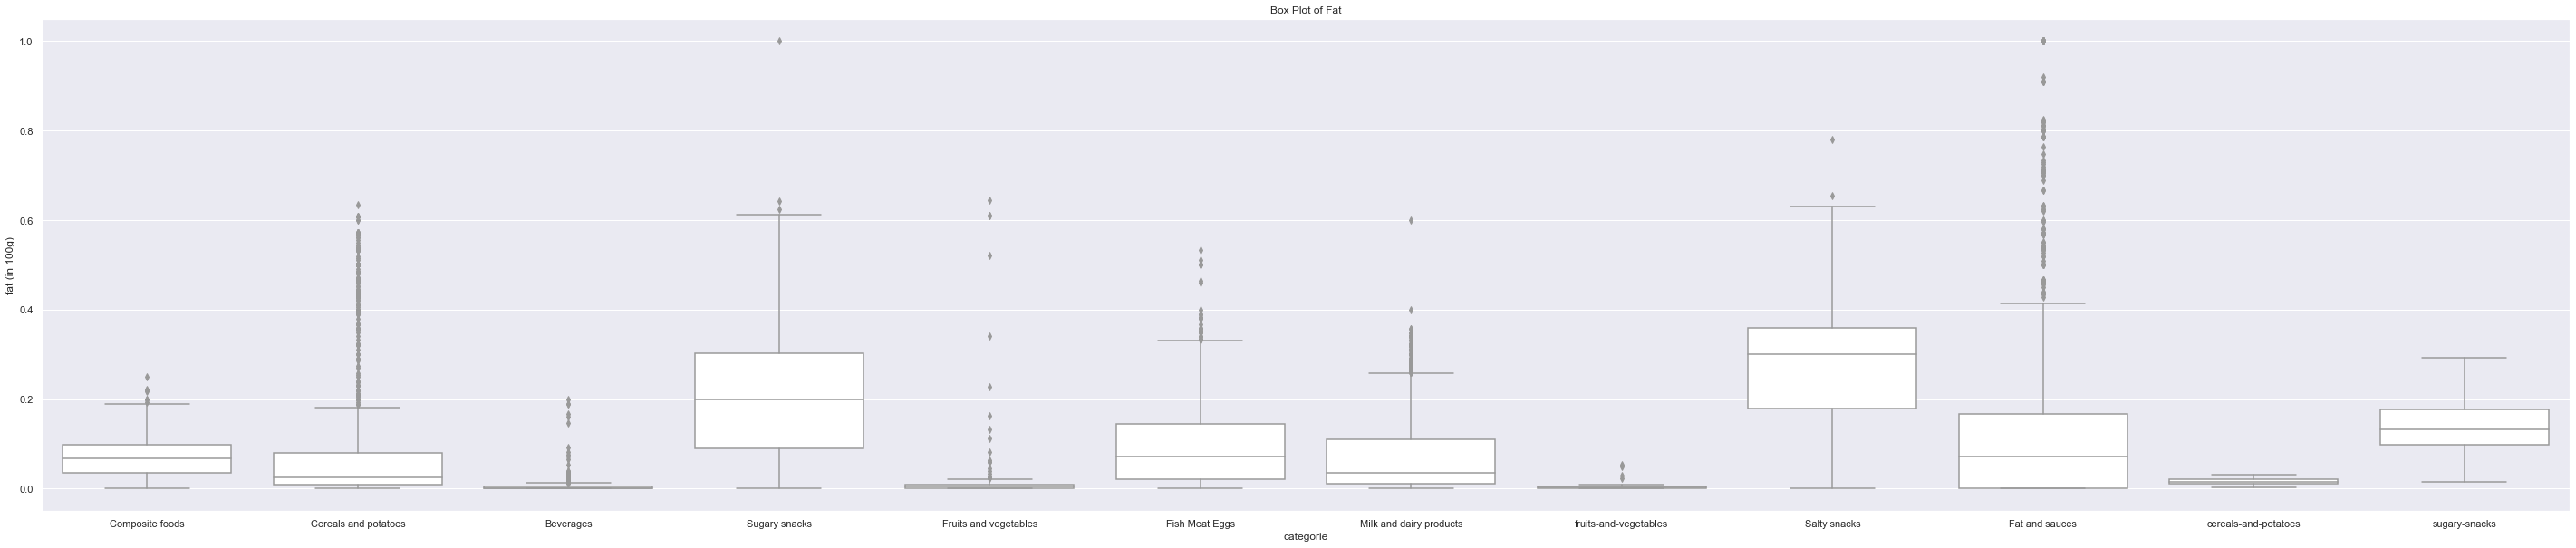

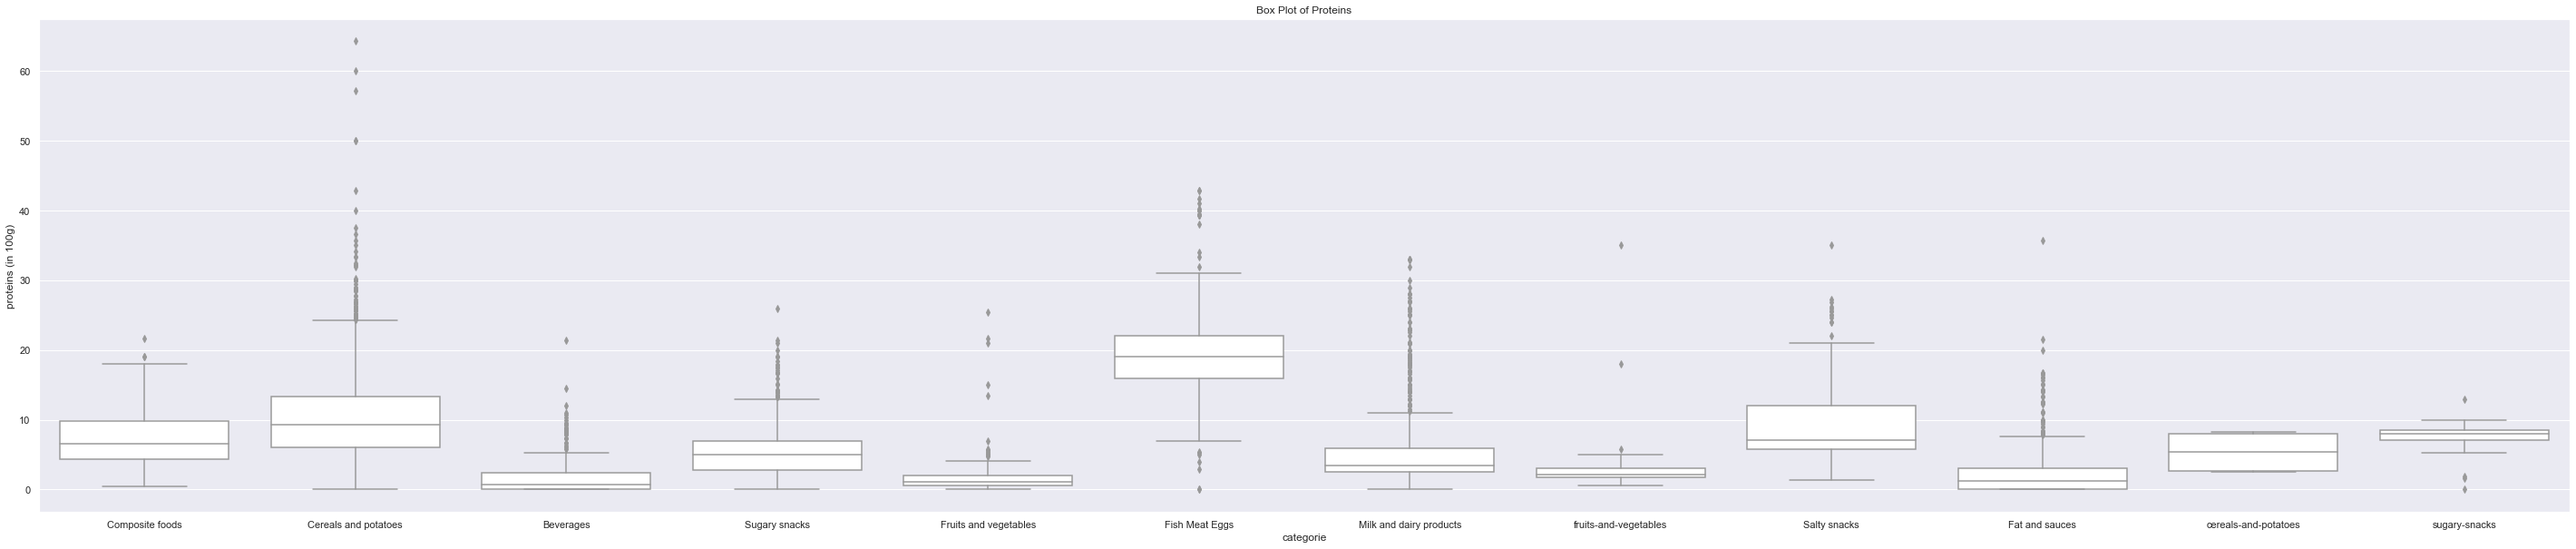

In [51]:
def boxplots():
    """
    This function creates 4 box plots of the columns "energy_100g", "sugars_100g", "fat_100g", and "proteins_100g".
    Each box plot has the categories represented by "pnns_group1" on the x-axis and the respective nutrient on the y-axis.

    Returns:
        None
    """
    import matplotlib.pyplot as plt
    import seaborn as sns

    fig, ax = plt.subplots(figsize=(30, 15))
   

    # Create a box plot of energy
    sns.boxplot(x="pnns_group1", y="fiber_100g", 
                data=nutri_app.sort_values(by='nutrition_grade_fr'), color='white')
    plt.xlabel('categorie')
    plt.ylabel('Fibres (in 100g)')
    plt.title('Box Plot of Energy')
    ax.tick_params(axis='x', labelsize=18)
    plt.show()
    
    # Create a box plot of sugars
    sns.boxplot(x="pnns_group1", y="sugars_100g", 
                data=nutri_app.sort_values(by='nutrition_grade_fr'), color='white')
    plt.xlabel('categorie')
    plt.ylabel('sugars (in 100g)')
    plt.title('Box Plot of Sugars')
    ax.tick_params(axis='x', labelsize=18)
    plt.show()
    
    # Create a box plot of fat
    sns.boxplot(x="pnns_group1", y="fat_100g", 
                data=nutri_app.sort_values(by='nutrition_grade_fr'), color='white')
    plt.xlabel('categorie')
    plt.ylabel('fat (in 100g)')
    plt.title('Box Plot of Fat')
    ax.tick_params(axis='x', labelsize=18)
    plt.show()
    
    # Create a box plot of proteins
    sns.boxplot(x="pnns_group1", y="proteins_100g", 
                data=nutri_app.sort_values(by='nutrition_grade_fr'), color='white')
    plt.xlabel('categorie')
    plt.ylabel('proteins (in 100g)')
    ax.tick_params(axis='x', labelsize=18)
    plt.title('Box Plot of Proteins')
    plt.show()

# Call the function
boxplots()

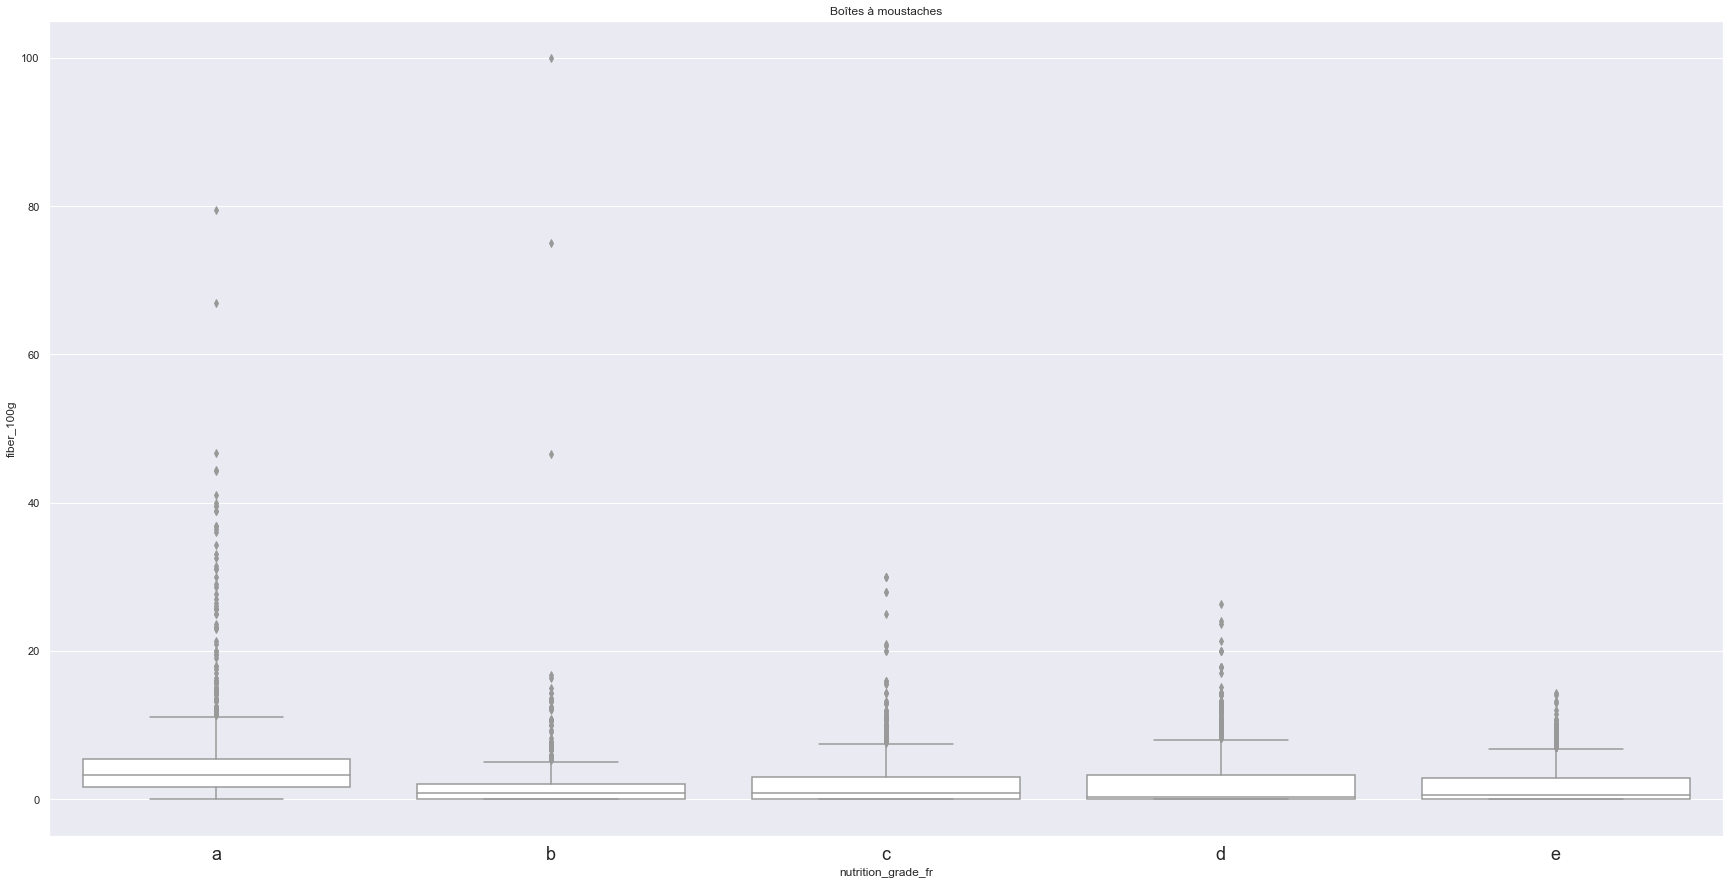

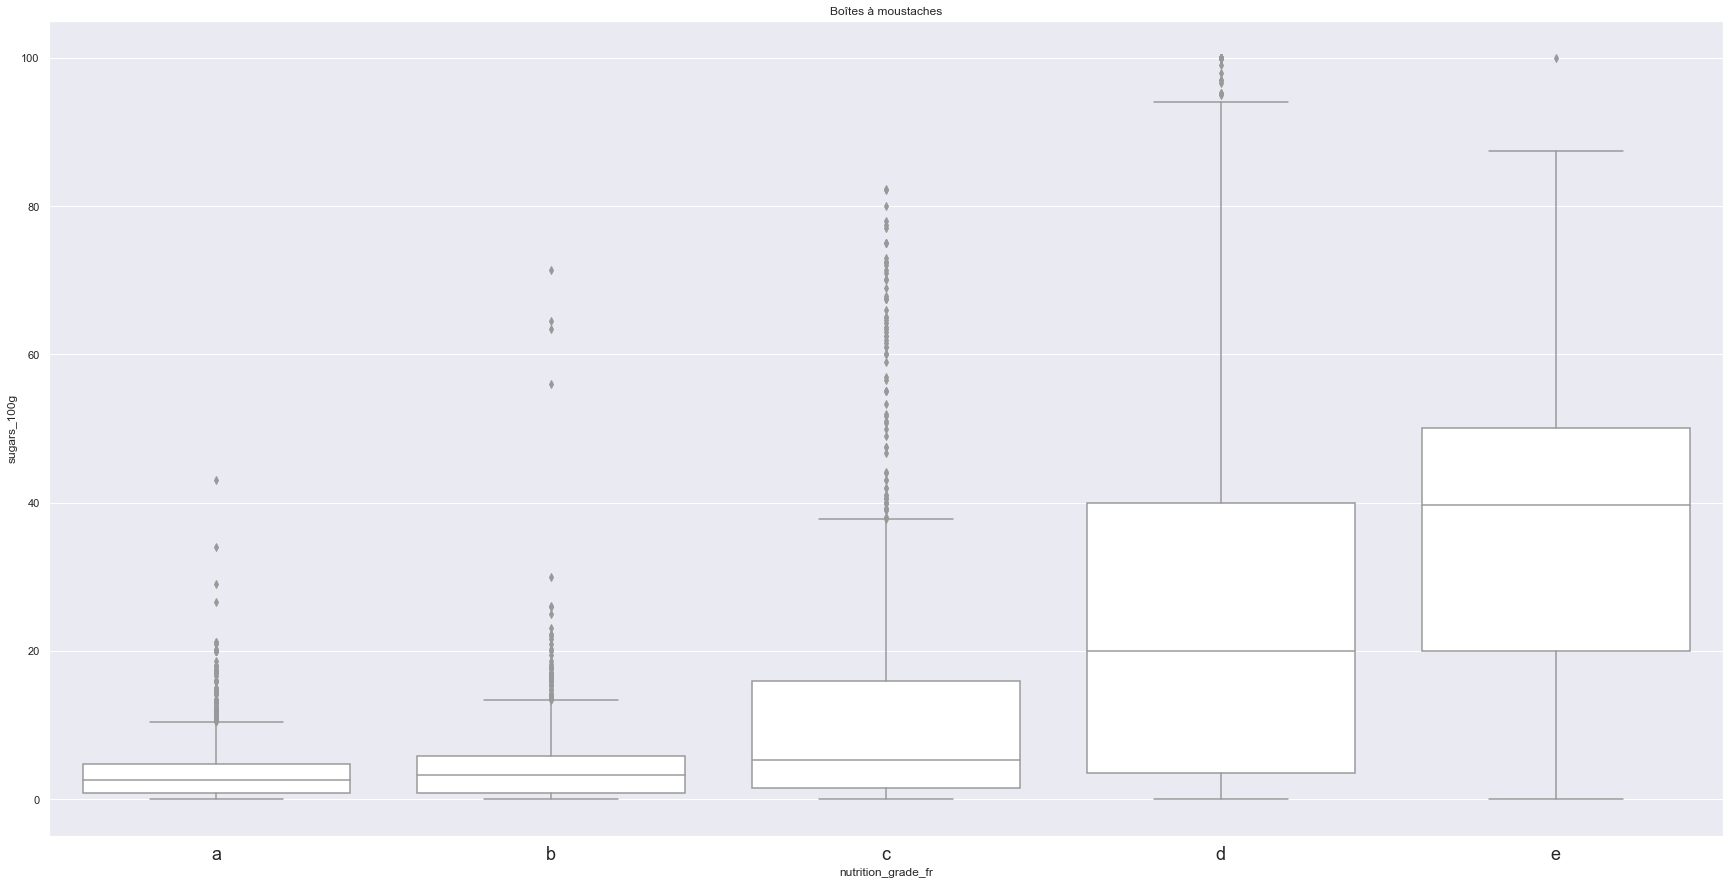

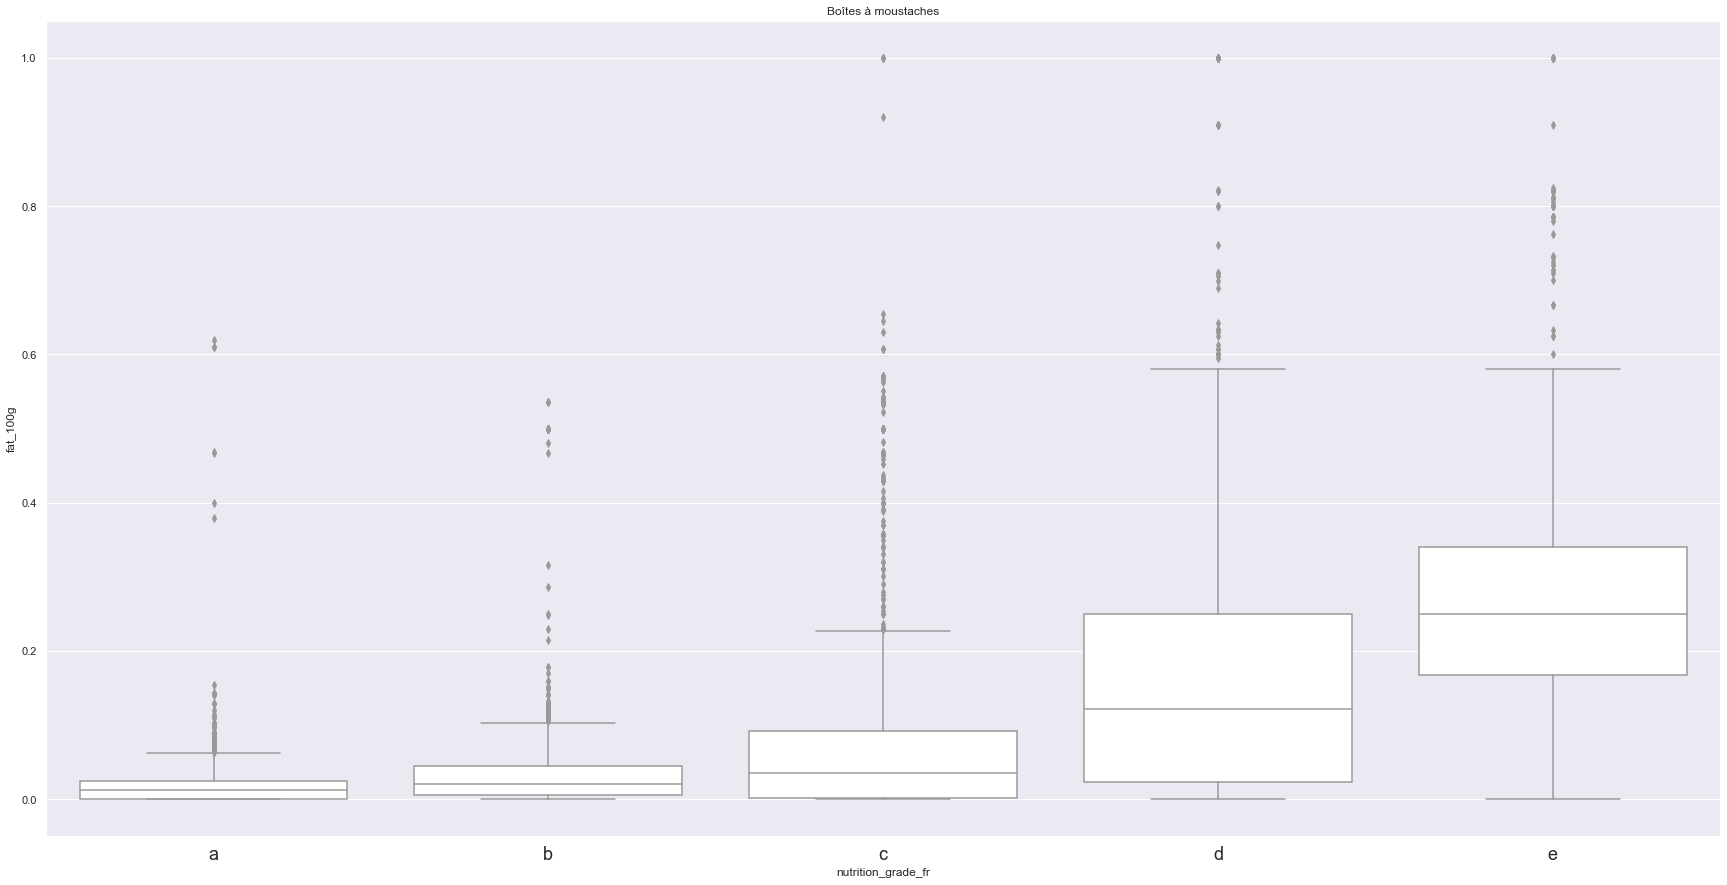

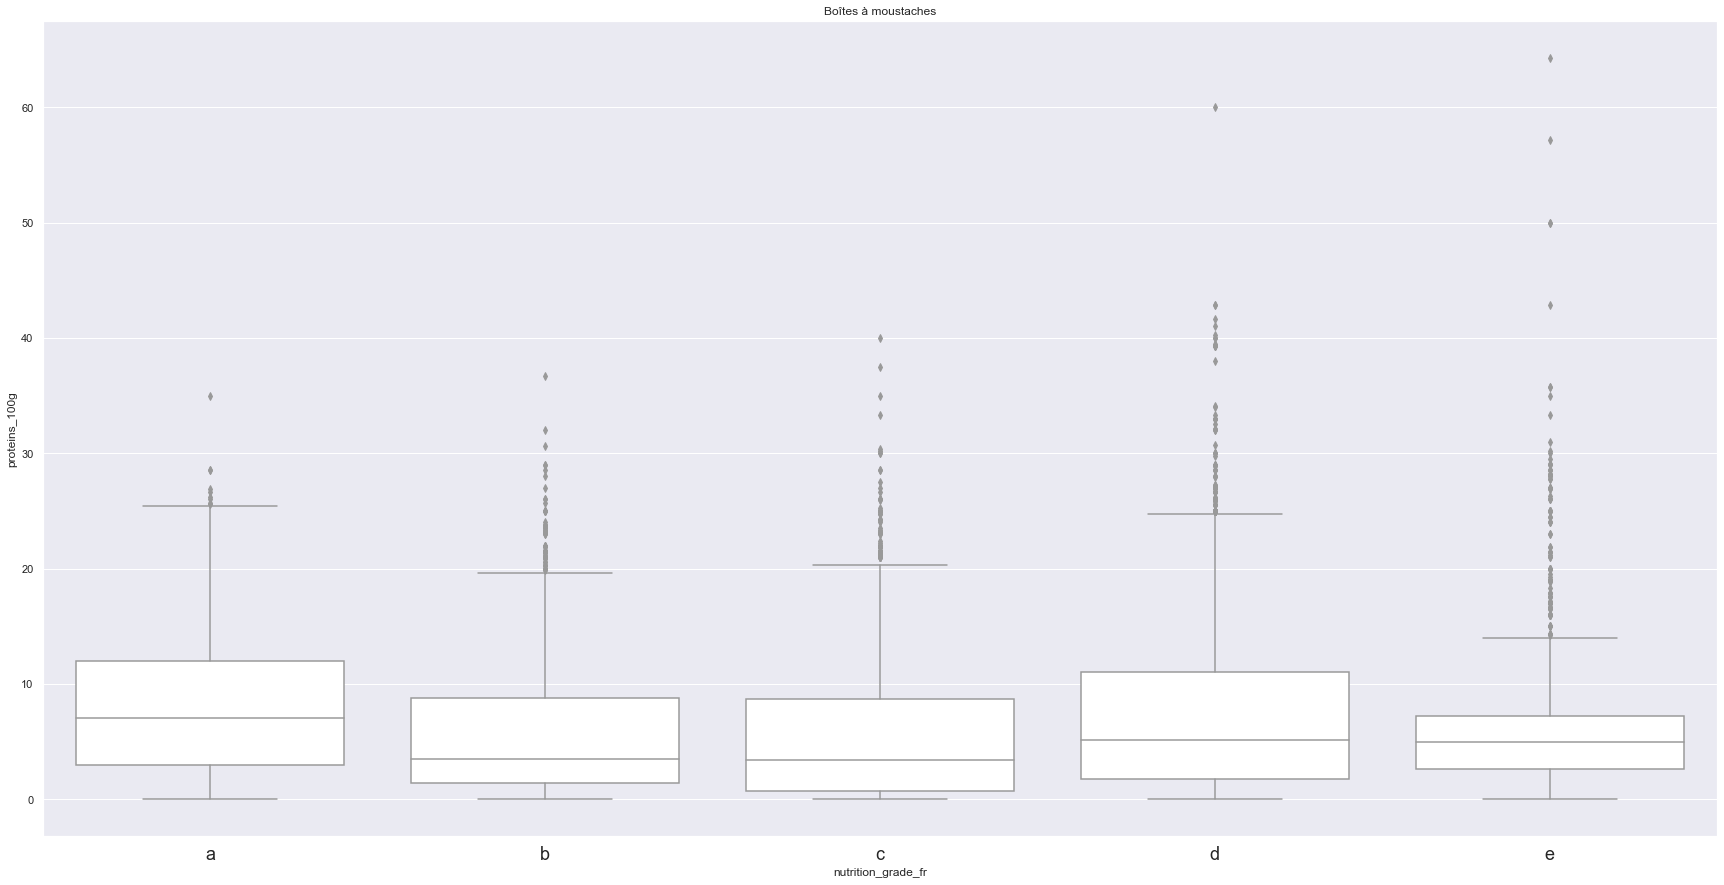

In [53]:

def plot_boxplot(columns):
    fig, ax = plt.subplots(figsize=(30, 15))
    ax = sns.boxplot(x="nutrition_grade_fr", y=columns, data=nutri_app.sort_values(by='nutrition_grade_fr'), color='white')
    plt.xlabel('nutrition_grade_fr')
    plt.ylabel(columns)
    plt.title('Boîtes à moustaches')
    ax.tick_params(axis='x', labelsize=18)
    plt.show()

plot_boxplot("fiber_100g")
plot_boxplot("sugars_100g")
plot_boxplot("fat_100g")
plot_boxplot("proteins_100g")

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">CCl : proportionnellement plus de nutriscore d pour le fat lorsque fat augmente, avec des outliers, a quand fat faible</p>

### matrice de corrélation

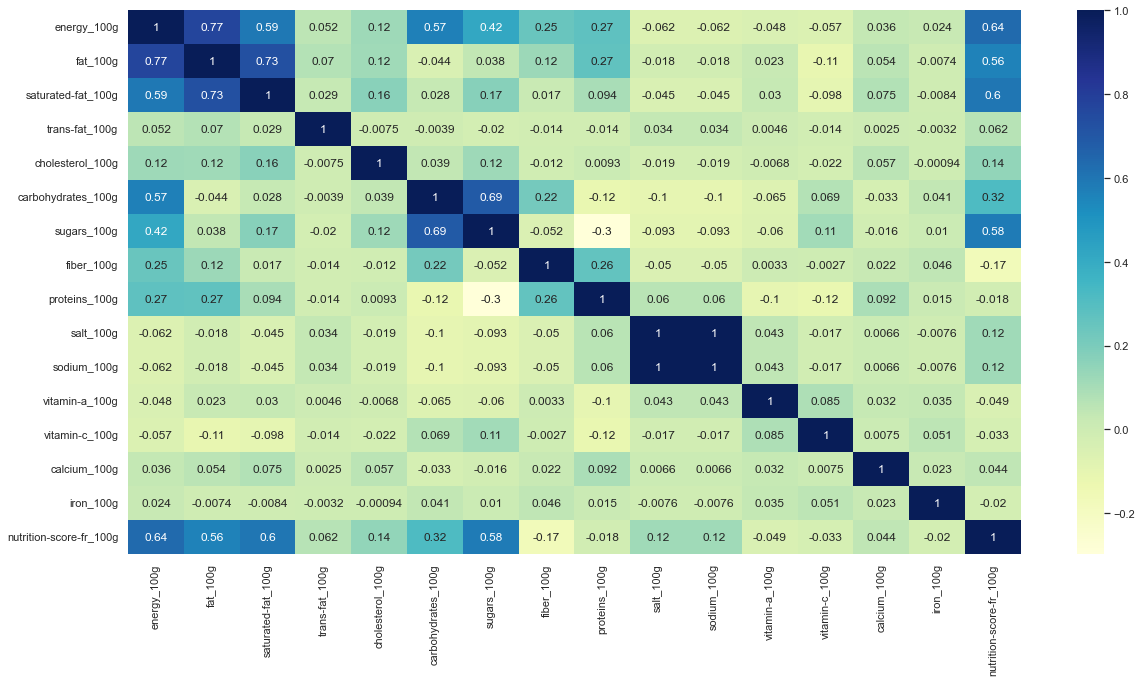

In [54]:
import seaborn as sn
import matplotlib.pyplot as plt

corr_matrix = nutri_app.corr()
sn.set(rc = {'figure.figsize':(20,10)})
sn.heatmap(corr_matrix, annot=True,cmap="YlGnBu")
plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> sodium et sel semble être les mêmes nutriments avec une corrélation = 1, <br> le sucre et les glucides sont étroitement liés.</p>

# Analyse multivariée

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> On se concentre sur fibre, sucre fat, protéines pour l'Anova et notre application de recommandation</p>

## Réduction de dimension par ACP / PCA

<div style="background-color:orange; color:dark;"> La PCA peut être utilisée pour réduire le nombre de variables à des dimensions plus petites qui peuvent être mieux comprises et exploitées par l'algorithme de recommandation. <br>
    Pour effectuer une ACP on utilise les données sur la composition des produits pour chaque nutriment pour créer une matrice de corrélation. 
    <br>Cette matrice permet ensuite de créer des dimensions qui représentent les produits en fonction de leur composition en nutriments. </div>

In [55]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [56]:
nutri_app.head(5)

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name
0,Sugary snacks,Chocolate products,2309.0,0.3300,19.00,0.0,10.900,50.00,50.00,2.1,4.90,0.08000,0.031496,0.000075,0.0000,0.268,0.00270,26.0,e,Extra Fondant
2,Fat and sauces,Alcoholic beverages,657.0,0.0000,0.00,0.0,0.000,35.71,30.00,1.4,0.00,0.03556,0.014000,0.000000,0.0000,0.000,0.00000,6.0,c,Jellied Cranberry Sauce
3,Fat and sauces,Alcoholic beverages,1109.0,0.2059,8.82,0.0,0.029,17.65,11.76,0.0,5.88,0.56134,0.221000,0.000353,0.0000,0.000,0.00000,15.0,d,"Brooks Street Bakery, Classic European Pastry ..."
7,Sugary snacks,Biscuits and cakes,1703.0,0.1852,1.85,0.0,0.056,55.56,38.89,1.9,5.56,0.46990,0.185000,0.000139,0.0022,0.019,0.00733,14.0,d,"Ready To Bake, Brownies Mix"
8,Sugary snacks,Chocolate products,1954.0,0.2667,13.33,0.0,0.022,55.56,42.22,2.2,4.44,0.19812,0.078000,0.000000,0.0000,0.133,0.00080,21.0,e,"Pixies, Milk Chocolate"


In [57]:
data_pca = nutri_app.select_dtypes(['float64','int32'])

In [58]:
colonnes_pca = data_pca.columns

In [59]:
scaler = StandardScaler()
data_pca = scaler.fit_transform(data_pca)

In [60]:
pca = PCA(n_components = data_pca.shape[1])

In [61]:
pca.fit(data_pca)

PCA(n_components=16)

In [62]:
pca.explained_variance_ratio_

array([2.11337882e-01, 1.32889641e-01, 1.14778560e-01, 8.54091948e-02,
       7.07841695e-02, 6.44787429e-02, 6.14027191e-02, 5.97573283e-02,
       5.74060853e-02, 5.47313478e-02, 3.88080192e-02, 2.10997662e-02,
       1.68629857e-02, 9.43779866e-03, 8.15760244e-04, 1.71067463e-10])

In [63]:
pca.singular_values_

array([1.49728830e+02, 1.18730506e+02, 1.10343598e+02, 9.51851216e+01,
       8.66532440e+01, 8.27037185e+01, 8.07068798e+01, 7.96181976e+01,
       7.80361296e+01, 7.61964657e+01, 6.41619410e+01, 4.73102864e+01,
       4.22945094e+01, 3.16411391e+01, 9.30246455e+00, 4.25991038e-03])

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
CCl : <br>
La méthode d'analyse en composantes principales (PCA) est une technique d'analyse statistique qui peut être utilisée pour réduire les variables explicatives à un nombre plus petit et plus gérable de variables explicatives. <br>En utilisant le PCA, les variables explicatives initiales peuvent être regroupées en un nombre plus petit de variables explicatives appelées composantes principales. 
    <br>Ces composantes principales peuvent ensuite être utilisées pour prédire le nutriscore à partir de la quantité de quatre nutriments.</p>

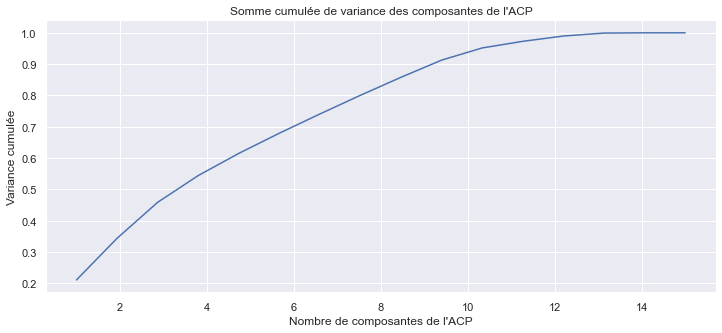

In [64]:
plt.figure(figsize=(12,5))
plt.title('Somme cumulée de variance des composantes de l\'ACP')
plt.xlabel('Nombre de composantes de l\'ACP')
plt.ylabel('Variance cumulée')
plt.plot(np.linspace(1, 15,16),
         np.cumsum(pca.explained_variance_ratio_))

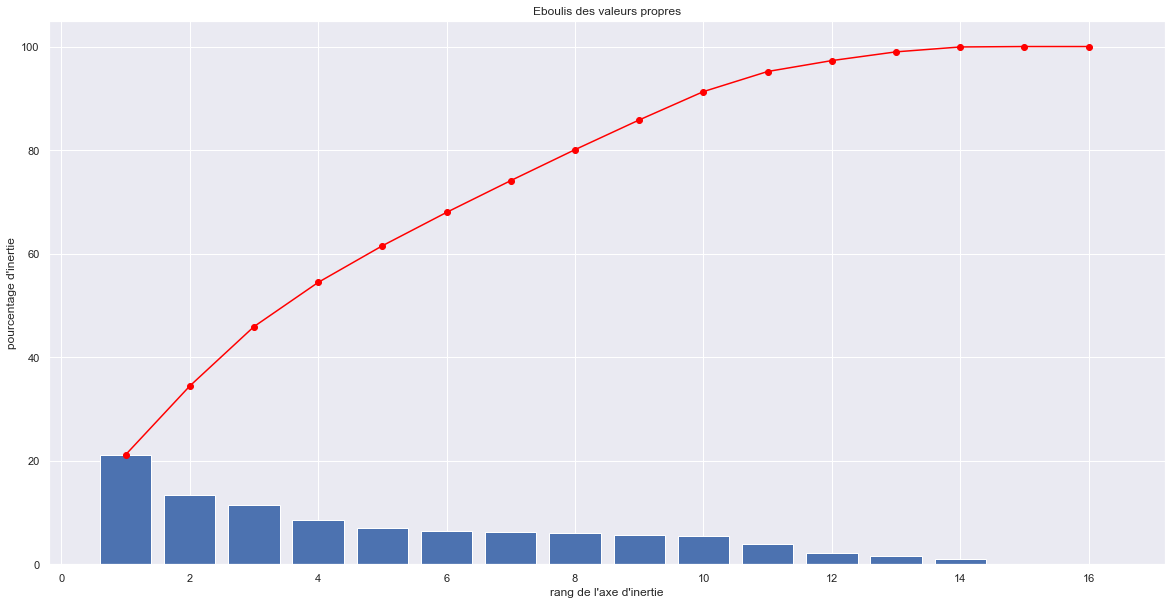

In [65]:
def display_scree_plot(pca):
    scree = pca.explained_variance_ratio_*100
    plt.bar(np.arange(len(scree))+1, scree)
    plt.plot(np.arange(len(scree))+1, scree.cumsum(),c="red",marker='o')
    plt.xlabel("rang de l'axe d'inertie")
    plt.ylabel("pourcentage d'inertie")
    plt.title("Eboulis des valeurs propres")
    plt.show(block=False)#graphique eboulis des valeurs propres
#pour la representation de nos individus 
display_scree_plot(pca)

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> On voit qu'à partir de 10 features on a une variance cumulée d'environ 90%. 
<br>Nous pouvons conclure que la représentation par des variables synthétiques ciblées ne sera pas optimale
</p>

In [66]:
pca.components_

array([[ 5.03239723e-01,  4.15776532e-01,  4.07180713e-01,
         3.43638368e-02,  1.23123144e-01,  2.74474372e-01,
         3.10137148e-01,  7.33863738e-02,  7.56810858e-02,
        -4.43641419e-02, -4.43640609e-02, -3.11024231e-02,
        -3.75927238e-02,  3.81615533e-02,  5.66713900e-03,
         4.48668679e-01],
       [ 1.55508726e-02,  1.97838482e-01,  1.30962261e-01,
         6.28436015e-02,  3.01177919e-03, -2.77749866e-01,
        -2.59817107e-01, -2.95561812e-02,  2.25805421e-01,
         5.97111781e-01,  5.97111774e-01,  5.00890357e-02,
        -1.16652132e-01,  5.97418222e-02, -2.49374381e-02,
         9.80024883e-02],
       [-6.75399582e-02, -3.05295548e-01, -1.88362875e-01,
         3.29948072e-05, -3.02276749e-03,  3.55268908e-01,
         4.57330819e-01, -2.18366368e-01, -4.16719834e-01,
         3.34929608e-01,  3.34929692e-01,  1.68187464e-02,
         1.95299105e-01, -9.62061328e-02,  5.01216165e-03,
         1.94872813e-01],
       [ 1.90555637e-01, -1.30521287e

In [67]:
pca.components_.shape

(16, 16)

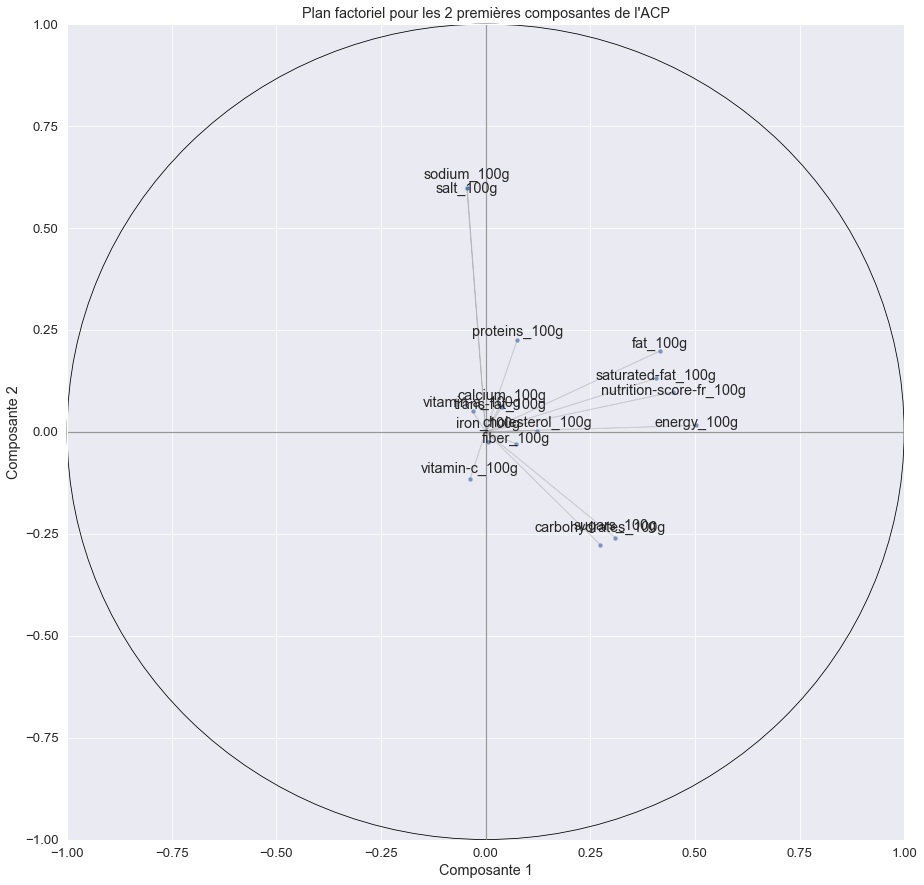

In [68]:
from matplotlib.patches import Circle
sns.set_context("paper", font_scale=1.5) 
plt.figure(figsize=(15,15))
chaine = "Plan factoriel pour les 2 premières composantes de l'ACP"
plt.title(chaine)
plt.xlabel('Composante 1')
plt.ylabel('Composante 2')
ax = plt.gca()
ax.add_patch(Circle([0,0], radius=1, color='black', fill=False, linestyle='-', clip_on=False))
ax.set_xlim(-1,1)
ax.set_ylim(-1,1)
x_pca = pca.components_[0,:]
y_pca = pca.components_[1,:]

sns.scatterplot(x = x_pca,
                y = y_pca,
               alpha = 0.7)
plt.plot([-1,1],[0,0], color='grey', alpha=0.8)
plt.plot([0,0],[-1,1], color='grey', alpha=0.8)

i = 0
for x,y,colonne in zip(x_pca,y_pca, colonnes_pca):

    plt.annotate(colonne, 
                 (x,y), 
                 textcoords="offset points", 
                 xytext=(0,5+np.random.randint(-10,10)),
                 ha='center') 
    ax.arrow(0, 0, x, y, head_width=0, head_length=0, fc='grey', ec='grey',alpha=0.2)


sns.set_context("paper", font_scale=1) 

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
CCl : <br>Les variables les plus fortement corrélées avec le premier axe principal d'inertie F1 sont <br> energy, fat, nutriscore <br> Les variables les plus fortement corrélées avec le premier axe principal d'inertie F2 sont sodium, protein
    interpretation : <strong>quantite ordonnées et abscisses nutriscore</strong><br/>
    fat_100g et saturated-fat_100g expliquent bien la variance sur la composante 1 mais pas sur la composante 2<br>
sodium_100g et salt_100g sont quasi confondus : les variables sont corrélées positivement<br>
carbohydrates_100g et sugars_100g sont très proches et donc également corrélées positivement :<br>
carbohydrates_100g, sugars_100g, sodium_100g et salt_100g expliquent bien la variance sur la composante 2, moins sur la composante 1..</p>

In [69]:
pca_analysis = pd.DataFrame(pca.components_)
pca_analysis.columns = colonnes_pca

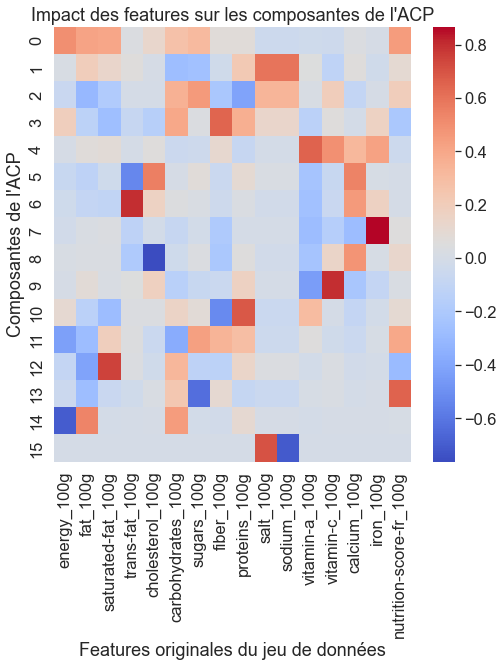

In [70]:
sns.set(font_scale=1.5)
plt.figure(figsize=(8,8))
sns.set
sns.heatmap(pca_analysis, cmap='coolwarm')
plt.title('Impact des features sur les composantes de l\'ACP')
plt.xlabel('Features originales du jeu de données')
plt.ylabel('Composantes de l\'ACP')
sns.set(font_scale=1)

In [71]:
norms = np.linalg.norm(pca.components_[0:6], axis=0)
normes = pd.DataFrame(norms).T

In [72]:
normes.columns = colonnes_pca

In [73]:
normes = normes.T.reset_index()

In [74]:
normes.columns = ['feature', 'norme']
normes.sort_values(by='norme', inplace=True, ascending=False)

<AxesSubplot:title={'center':"Importance relative des features dans \n les 10 premières composantes de l'ACP"}, xlabel='norme', ylabel='feature'>

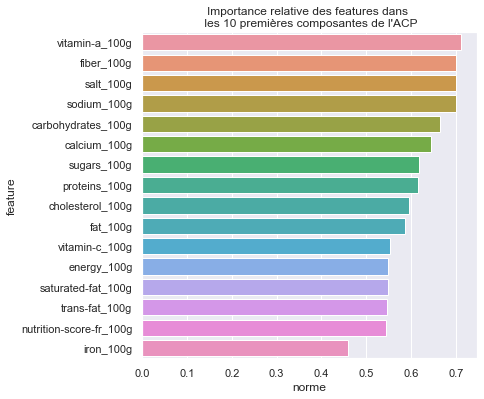

In [75]:
plt.figure(figsize=(6,6))
plt.title('Importance relative des features dans \n les 10 premières composantes de l\'ACP')
sns.barplot(y = normes['feature'],
            x = normes['norme'])

In [76]:
nutri_app.columns

Index(['pnns_group1', 'pnns_group2', 'energy_100g', 'fat_100g', 'saturated-fat_100g', 'trans-fat_100g', 'cholesterol_100g', 'carbohydrates_100g', 'sugars_100g', 'fiber_100g', 'proteins_100g', 'salt_100g', 'sodium_100g', 'vitamin-a_100g', 'vitamin-c_100g', 'calcium_100g', 'iron_100g', 'nutrition-score-fr_100g', 'nutrition_grade_fr', 'product_name'], dtype='object')

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> nous n'allons pas faire l'anova sur toutes les variables. On se sert du cercle de corrélation de l'ACP pour choisir nos variables</p>

## ANOVA (Analyse de variance)

<div style="background-color:orange; color:dark;"><strong>Objectifs:</strong><br>
to test the statistical differences between the means of the nutrient scores for each component</div>

<div style="background-color:orange; color:dark;">H0: there are no differences between the average nutrient scores for each food component
H1: the averave nutrient scores for each food group are different from each other</div>

<div style="background-color:orange; color:dark;">conditions ANOVA :<br>
•Les échantillons sont indépendants les uns des autres. <br>
•Les données sont normalement distribuées.<br>
•Les variances intragroupes sont homogenes</div>

<div style="background-color:orange; color:dark;"> Independence of observations:✅</div>

Independence of observations: the data were collected using statistically valid sampling methods, and there are no hidden relationships among observations. If your data fail to meet this assumption because you have a confounding variable that you need to control for statistically, use an ANOVA with blocking variables.

<div style="background-color:orange; color:dark;"> Normally-distributed response variable❌</div>

In [77]:
nutri_app[['fiber_100g', 'sugars_100g','fat_100g','proteins_100g']].describe()

,fiber_100g,sugars_100g,fat_100g,proteins_100g
count,6630.000000,6630.000000,6630.000000,6630.000000
mean,2.575482,17.977074,0.125165,6.956714
std,4.456194,21.778143,0.163616,7.100317
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,1.812500,0.006100,1.670000
50%,1.200000,6.670000,0.050000,5.000000
75%,3.400000,30.000000,0.199750,9.520000
max,100.000000,100.000000,1.000000,64.290000


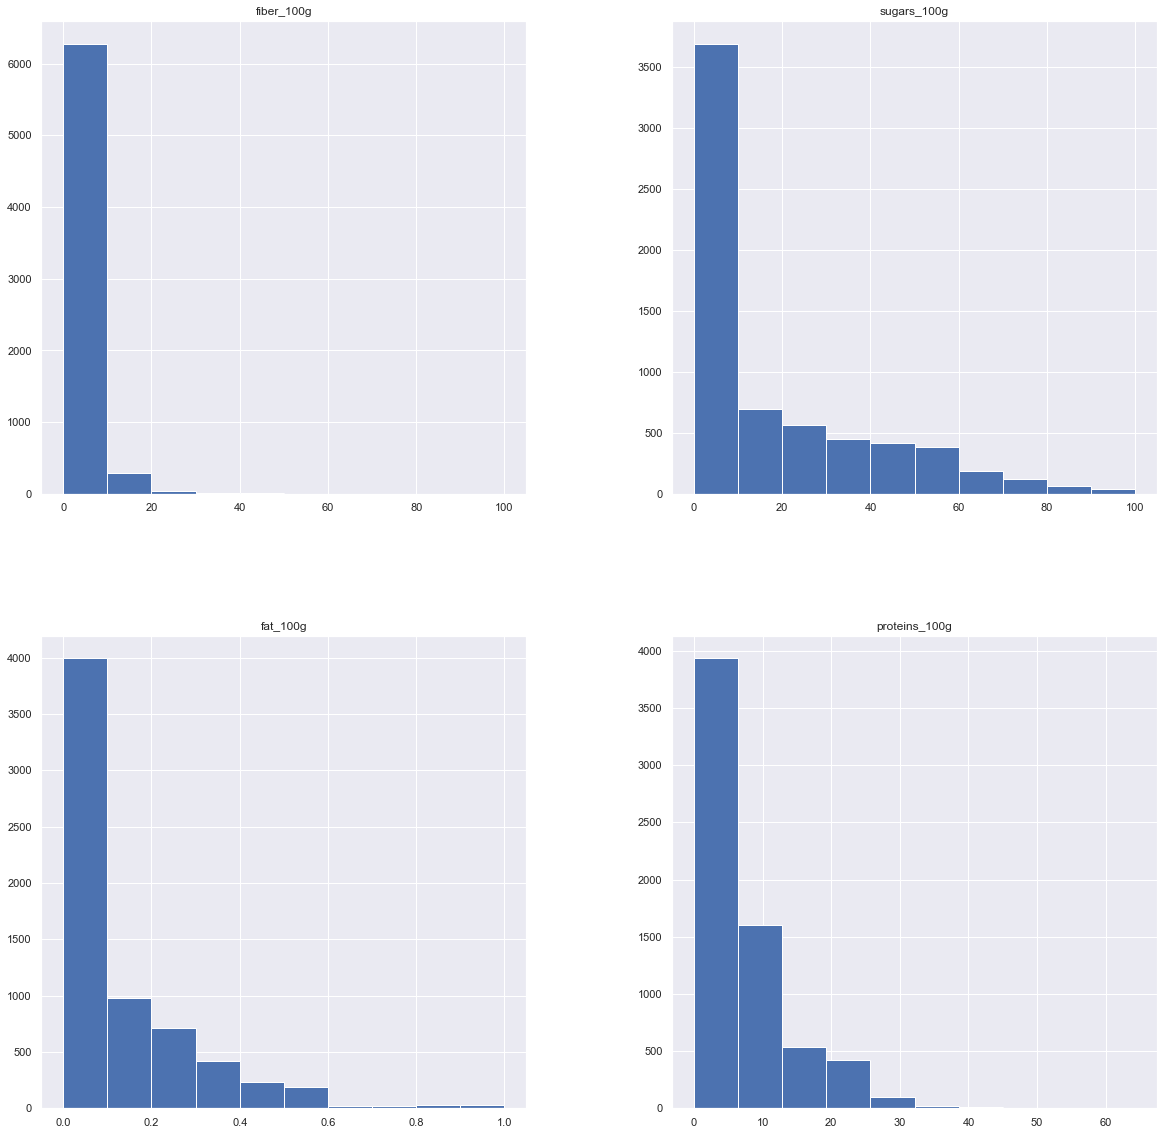

In [78]:
nutri_app[['fiber_100g', 'sugars_100g','fat_100g','proteins_100g']].hist(figsize=(20,20))
plt.show()

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> les variables quanti ne suivent pas une distribution normale
</p>

In [79]:
from scipy.stats import shapiro

# Sélectionnez vos colonnes à tester
cols = ['fiber_100g', 'sugars_100g','fat_100g','proteins_100g']

# Appliquer le test de Shapiro-Wilk aux colonnes sélectionnées
for col in cols:
  stat, p = shapiro(nutri_app[col])
  print('Colonne: {}, Stat: {:.3f}, p-valeur: {:.3f}'.format(col, stat, p))


Colonne: fiber_100g, Stat: 0.555, p-valeur: 0.000
Colonne: sugars_100g, Stat: 0.796, p-valeur: 0.000
Colonne: fat_100g, Stat: 0.767, p-valeur: 0.000
Colonne: proteins_100g, Stat: 0.841, p-valeur: 0.000


/Users/laureagrech/opt/anaconda3/lib/python3.9/site-packages/scipy/stats/morestats.py:1760: UserWarning: p-value may not be accurate for N > 5000.
  warnings.warn("p-value may not be accurate for N > 5000.")


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl </strong>: La p-valeur indique la probabilité que les données observées proviennent d'une distribution normale. Dans ce cas, les p-valeurs sont très faibles, ce qui signifie que les données ne suivent pas une distribution normale.</o> 

La seule variable est le nutriscore. 
On teste ANOVA pour comparer les différents niveaux du nutriscore (A à E) avec les valeurs nutritionnelles pour chaque composante nutritionnelle (énergie, sucre, gras, protéines).
Pour améliorer la précision et la fiabilité des résultats on normalisera les composantes nutritionnelles avant d'exécuter un test ANOVA
Pour ce faire on utilise la méthode de normalisation 

## Normalisation Anova

In [80]:
# Importe la bibliothèque scikit-learn
from sklearn import preprocessing

# Sélectionnez vos colonnes à normaliser
cols = ['fiber_100g', 'sugars_100g','fat_100g','proteins_100g']
# Créez un objet de normalisation
scaler = preprocessing.StandardScaler()

# Applique la normalisation aux colonnes sélectionnées
normalized_df = scaler.fit_transform(nutri_app[cols])

# Ajoute les colonnes normalisées à votre jeu de données
df_normalized = nutri_app.copy()
df_normalized[cols] = normalized_df

In [81]:
# Crée un dictionnaire pour attribuer des valeurs numériques aux différents niveaux de nutriscore
score_dict = {'a':1, 'b':2, 'c':3, 'd':4, 'e':5}

# Applique le dictionnaire aux données
nutri_app['nutriscore_num'] = nutri_app['nutrition_grade_fr'].map(score_dict)

/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_22716/4267157578.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  nutri_app['nutriscore_num'] = nutri_app['nutrition_grade_fr'].map(score_dict)


In [82]:
# Importer la bibliothèque scipy
from scipy.stats import f_oneway

# Sélectionnez vos colonnes à tester
cols = ['fiber_100g', 'sugars_100g','fat_100g','proteins_100g']

# Appliquer le test ANOVA aux colonnes sélectionnées
for col in cols:
  stat, p = f_oneway(nutri_app[col], nutri_app['nutriscore_num'])
  print('Colonne: {}, Stat: {:.3f}, p-valeur: {:.3f}'.format(col, stat, p))


Colonne: fiber_100g, Stat: 107.172, p-valeur: 0.000
Colonne: sugars_100g, Stat: 3052.883, p-valeur: 0.000
Colonne: fat_100g, Stat: 31402.838, p-valeur: 0.000
Colonne: proteins_100g, Stat: 1817.270, p-valeur: 0.000


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;"><strong>CCl:</strong> p<0 we can reject the null hypothesis and conclude that the average nutrient scores of certain components is different <br>Une valeur de "Stat" élevée signifie que les moyennes des différents niveaux sont significativement différentes.<br>
<br>Les p-valeurs indiquent que la différence entre les moyennes des différents niveaux du nutriscore et les valeurs nutritionnelles est significativement différente. Les valeurs élevées du statut suggèrent que les différences entre les moyennes des différents niveaux sont importantes.<br>L'ANOVA indique que les différences entre les moyennes des différents niveaux du nutriscore et les valeurs nutritionnelles sont significativement différentes. <br>Cela suggère que le nutriscore a une influence statistiquement significative sur les valeurs nutritionnelles.<br>
Les niveaux du nutriscore sont donc liés aux valeurs nutritionnelles.
</p>

<div style="background-color:orange; color:dark;"> Les variances intragroupes sont homogenes</div>

In [83]:
#import the necessary packages
import numpy as np
import pandas as pd

#read the dataset
df = nutri_app

#calculate the variance for each of the four columns
variance_fiber = df['fiber_100g'].var()
variance_sugars = df['sugars_100g'].var()
variance_fat = df['fat_100g'].var()
variance_proteins = df['proteins_100g'].var()

#calculate the overall variance
overall_variance = np.mean([variance_fiber, variance_sugars, variance_fat, variance_proteins])

#calculate the homogeneity of variance
homogeneity_of_variance = np.std([variance_fiber, variance_sugars, variance_fat, variance_proteins]) / overall_variance

print(homogeneity_of_variance)

1.4399851411697941


Un autre critère de l'ANOVA est l'égalité des variances. On utilise le test de Levene pour voir si les variances sont les mêmes au sein des groupes

In [84]:
from scipy.stats import levene
stat, p = levene(df['fiber_100g'], df['sugars_100g'], df['fat_100g'],df['proteins_100g'])
print(p)


0.0



Si la p-valeur imprimée est supérieure à 0,05, cela signifie que les variances des groupes sont homogènes et que le test ANOVA peut être utilisé.

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">CCl: Ce résultat indique que la variance des quatre colonnes n'est pas uniforme. Plus le résultat est proche de 0, plus la variance est uniforme.
</p> 

<div style="background-color:orange; color:dark;"> Pour que l'ANOVA fonctionne, il faut que les données respectent certaines conditions. <br>Ces conditions comprennent un échantillonnage aléatoire, une normalité des données, une homoscédasticité et une absence de multicolinéarité. Ces conditions ne sont pas respectées.<br> Par conséquent, l'ANOVA n'est pas l'outil les plus adaptés pour ce projet.</div>

# alternative non paramétrique à l'Anova


## Kruskal-Wallis

<div style="background-color:orange; color:dark;"> La méthode Kruskal-Wallis est une alternative non paramétrique à l'ANOVA. <br>On l'utilise pour comparer les moyennes de plusieurs populations indépendantes. 
    <br>Similaire à l'ANOVA, à l'exception du fait qu'elle ne suppose pas que les données suivent une distribution normale. <br>Elle est également plus robuste que l'ANOVA, ce qui signifie qu'elle est moins sensible aux données aberrantes.<br><br> Le test de Kruskal-Wallis sert à déterminer si plusieurs distributions de données sont identiques ou non. Il est utile pour comparer les différences entre différents groupes ou pour <strong>déterminer si une variable explicative a un effet statistiquement significatif sur une variable cible.</strong></div>

Avant de faire le test de Kruskal-Wallis, il est important de formuler les hypothèses nulles et alternatives. Le test de Kruskal-Wallis permet de déterminer s'il y a une différence significative entre les distributions de deux ou plusieurs groupes, mais il ne permet pas d'identifier quelle(s) distribution(s) est(sont) différente(s) des autres. Les hypothèses sont les suivantes :

<strong>Ho : Les distributions de nutriments sont égales dans tous les grades nutritionnels (A, B, C, D, E).</strong> <br><br>
<strong>H1 : Au moins une des distributions de nutriments est différente dans les grades nutritionnels.</strong> <br>
Le test de Kruskal-Wallis permet de rejeter ou d'accepter l'hypothèse nulle en fonction de la valeur p. <br><br>
>  -Si la valeur p est inférieure à un seuil de signification choisi (généralement 0,05), l'hypothèse nulle est rejetée et l'hypothèse alternative est acceptée. Cela indique qu'il y a une différence significative entre au moins deux des distributions de nutriments dans les grades nutritionnels. 
<br> <br> 
>  -Si la valeur p est supérieure au seuil de signification, l'hypothèse nulle est acceptée et il n'y a pas de différence significative entre les distributions de nutriments dans les grades nutritionnels.

Les résultats de ce test de Kruskal-Wallis vont vous aider à déterminer si les nutriments que vous électionnés (fibres, sucres, graisses et protéines) ont un impact statistiquement significatif sur le nutriscore. La valeur p vous dis si les différences observées sont le résultat d'un hasard ou si elles sont statistiquement significatives. Si la valeur p est inférieure à 0,05, cela signifie que les différences entre les nutriments et le nutriscore sont statistiquement significatives.

<div style="background-color:orange; color:dark;">Boîte à moustache représentant la distribution de chaque nutriment par nutriscore<br><br>
    test de Kruskal-Wallis sur chaque nutriment pour déterminer s'il existe des différences significatives dans les distributions de nutriments entre différents grades nutritionnels :</div>

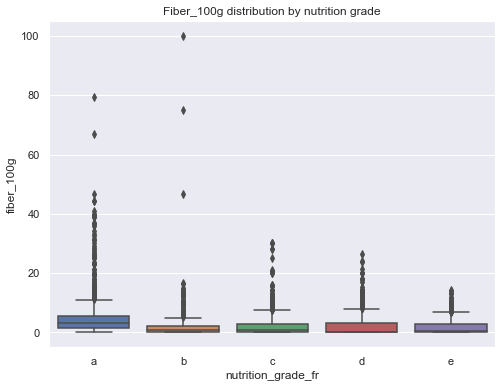

Kruskal-Wallis test p-value for fiber_100g: 2.297266014738548e-135


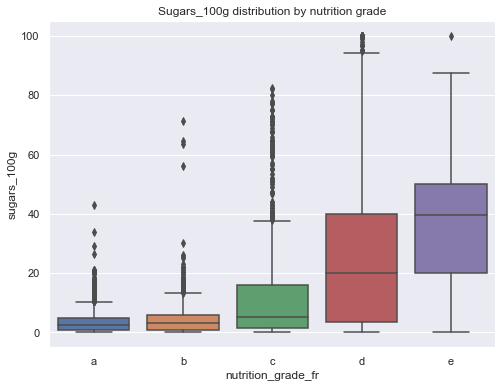

Kruskal-Wallis test p-value for sugars_100g: 0.0


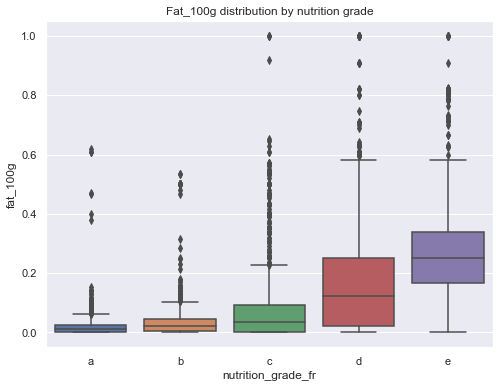

Kruskal-Wallis test p-value for fat_100g: 0.0


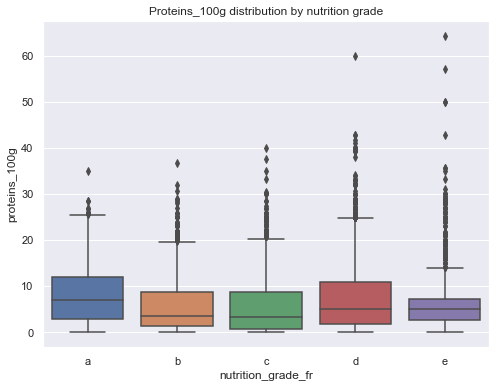

Kruskal-Wallis test p-value for proteins_100g: 6.0475629904770916e-33


In [85]:
import pandas as pd
import seaborn as sns
from scipy.stats import kruskal
grades=['a', 'b', 'c', 'd', 'e']
nutrients = ['fiber_100g', 'sugars_100g', 'fat_100g', 'proteins_100g']
for nutrient in nutrients:
    plt.figure(figsize=(8, 6))
    sns.boxplot(x='nutrition_grade_fr', y=nutrient, data=nutri_app, order=grades)
    plt.title(nutrient.capitalize() + ' distribution by nutrition grade')
    plt.show()
    
    # test de Kruskal-Wallis :
    groups = [nutri_app.loc[nutri_app['nutrition_grade_fr']==grade, [nutrient]][nutrient].dropna() for grade in ['a', 'b', 'c', 'd', 'e']]
    _, p_value = kruskal(*groups)
    print('Kruskal-Wallis test p-value for ' + nutrient + ':', p_value)

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong>  ces résultats suggèrent que les aliments des différents groupes de nutrition grade (a,b,c,d,e) ont des compositions nutritionnelles significativement différentes en termes de teneurs en fibres, sucres, matières grasses et protéines.
    </p>

## Regression lineaire

<div style="background-color:orange; color:dark;"> La régression linéaire est une technique d'apprentissage automatique qui permet de prédire une variable à partir d'autres variables. Elle peut être utile pour étudier les relations entre les variables et pour prédire des résultats.</div>



<div style="background-color:orange; color:dark;"><strong> Objectif :</strong> 
    <br> Montrer si les nutriments ont un impact statistiquement significatif sur le nutriscore.
 <br> <br> affecter un coefficient à chaque nutriments de l'application de recommendation</div>
    
    

In [86]:
import statsmodels.api as sm

# Create the independent and dependent variables
X = nutri_app[['fiber_100g', 'sugars_100g', 'fat_100g', 'proteins_100g']]
y = nutri_app['nutrition-score-fr_100g']

# Fit the regression model
model = sm.OLS(y, X).fit()

# Print the summary of the model
print(model.summary())

                                   OLS Regression Results                                   
Dep. Variable:     nutrition-score-fr_100g   R-squared (uncentered):                   0.830
Model:                                 OLS   Adj. R-squared (uncentered):              0.830
Method:                      Least Squares   F-statistic:                              8103.
Date:                     Sun, 12 Mar 2023   Prob (F-statistic):                        0.00
Time:                             19:38:50   Log-Likelihood:                         -20544.
No. Observations:                     6630   AIC:                                  4.110e+04
Df Residuals:                         6626   BIC:                                  4.112e+04
Df Model:                                4                                                  
Covariance Type:                 nonrobust                                                  
                    coef    std err          t      P>|t|      [0.025 

<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">Les résultats de la régression linéaire montrent que les coefficients de régression des nutriments sont statistiquement significatifs (P <0,05). <br>Cela signifie que les nutriments ont un impact statistiquement significatif sur le nutriscore.</p>

In [87]:
nutri_app.head(2)

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name,nutriscore_num
0,Sugary snacks,Chocolate products,2309.0,0.33,19.0,0.0,10.9,50.00,50.0,2.1,4.9,0.08000,0.031496,0.000075,0.0,0.268,0.0027,26.0,e,Extra Fondant,5
2,Fat and sauces,Alcoholic beverages,657.0,0.00,0.0,0.0,0.0,35.71,30.0,1.4,0.0,0.03556,0.014000,0.000000,0.0,0.000,0.0000,6.0,c,Jellied Cranberry Sauce,3


In [88]:
# Importer MinMaxScaler
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression

# Créer une copie du dataframe
nutri_app_scaled = nutri_app.copy()

# Créez un objet scaler
scaler = MinMaxScaler()

# Définissez vos caractéristiques et étiquettes
features = ['fiber_100g', 'sugars_100g','fat_100g','proteins_100g']
labels = nutri_app_scaled['nutrition-score-fr_100g']

# Appliquez le scaler aux données
nutri_app_scaled[features] = scaler.fit_transform(nutri_app[features])

# Créez un objet de régression linéaire
reg = LinearRegression()

# Entraînez le modèle avec vos données
reg.fit(nutri_app_scaled[features], labels)

# Prédisez les résultats
predictions = reg.predict(nutri_app_scaled[features])

# Afficher les coefficients
print(reg.coef_)


[-47.08832771  24.69485443  31.8271918    5.40839573]


In [89]:
nutri_app_scaled

,pnns_group1,pnns_group2,energy_100g,fat_100g,saturated-fat_100g,trans-fat_100g,cholesterol_100g,carbohydrates_100g,sugars_100g,fiber_100g,proteins_100g,salt_100g,sodium_100g,vitamin-a_100g,vitamin-c_100g,calcium_100g,iron_100g,nutrition-score-fr_100g,nutrition_grade_fr,product_name,nutriscore_num
0,Sugary snacks,Chocolate products,2309.0,0.33000,19.00,0.0,10.9000,50.00,0.5000,0.0210,0.076217,0.08000,0.031496,0.000075,0.0000,0.26800,0.002700,26.0,e,Extra Fondant,5
2,Fat and sauces,Alcoholic beverages,657.0,0.00000,0.00,0.0,0.0000,35.71,0.3000,0.0140,0.000000,0.03556,0.014000,0.000000,0.0000,0.00000,0.000000,6.0,c,Jellied Cranberry Sauce,3
3,Fat and sauces,Alcoholic beverages,1109.0,0.20590,8.82,0.0,0.0290,17.65,0.1176,0.0000,0.091461,0.56134,0.221000,0.000353,0.0000,0.00000,0.000000,15.0,d,"Brooks Street Bakery, Classic European Pastry ...",4
7,Sugary snacks,Biscuits and cakes,1703.0,0.18520,1.85,0.0,0.0560,55.56,0.3889,0.0190,0.086483,0.46990,0.185000,0.000139,0.0022,0.01900,0.007330,14.0,d,"Ready To Bake, Brownies Mix",4
8,Sugary snacks,Chocolate products,1954.0,0.26670,13.33,0.0,0.0220,55.56,0.4222,0.0220,0.069062,0.19812,0.078000,0.000000,0.0000,0.13300,0.000800,21.0,e,"Pixies, Milk Chocolate",5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9990,Fat and sauces,Dressings and sauces,160.0,0.03000,0.10,0.0,0.0000,6.20,0.0560,0.0200,0.026443,0.50000,0.196850,0.000180,0.0072,0.01600,0.001150,0.0,b,Chunky Tomato Sauce,2
9991,Milk and dairy products,Ice cream,1149.0,0.14900,10.00,0.0,0.0118,31.80,0.2490,0.0030,0.048219,0.19000,0.074803,0.000210,0.0000,0.37700,0.000000,17.0,d,Mars Ice Cream,4
9993,Beverages,Non-sugared beverages,199.0,0.00625,0.00,0.0,0.0000,8.75,0.0792,0.0000,0.032353,0.00000,0.000000,0.000000,0.0000,0.00833,0.000300,0.0,b,Honey Soy Drink,2
9997,Fruits and vegetables,Vegetables,85.0,0.00700,0.14,0.0,0.0000,0.10,0.0005,0.0158,0.043553,0.14500,0.057087,0.000000,0.0000,0.01740,0.000626,-8.0,a,Jeunes pousses d'épinard,1


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
    <strong>Ccl :</strong> pour 1 g de fibre ajouté à un produit, le nutriscore baisse de -0,47</p>

In [90]:
nutri_app_scaled[features + ["nutrition-score-fr_100g"]].loc[[7, 8]]

,fiber_100g,sugars_100g,fat_100g,proteins_100g,nutrition-score-fr_100g
7,0.019,0.3889,0.1852,0.086483,14.0
8,0.022,0.4222,0.2667,0.069062,21.0


Exemple avec un aliment dont j'ai la composition :<br>
nutrition_score = (-47.08832771 * fibres) + (24.69485443 * sucres) + (31.8271918 * matieres_grassess) + (5.40839573 * proteines) ✅



# !! diviser par 100 car scaled

<p style="font-family:Arial; font-size:1.2em; background-color:#33030d; padding:10px; >
&nbsp&nbsp&nbsp&nbsp&nbsp&nbspL'application de recommandation de nutrition utilisera un algorithme intégrant le <em>Nutriscore</em>, le <strong>nom des produits</strong> et leur <strong>catégorie</strong> pour conseiller aux utilisateurs d'autres produits appartenant à la même catégorie ayant un <strong>Nutriscore optimal</strong>.  <br/> <br/>
&nbsp&nbsp&nbsp&nbsp&nbsp&nbspLe <strong>Nutriscore</strong> est une échelle de A à E, avec A étant le niveau le plus sain et E étant le niveau le moins sain. Le nom des produits et leurs catégories seront tirés d'une <strong>base de données des produits alimentaires</strong>. 
    <br/> <br/>
&nbsp&nbsp&nbsp&nbsp&nbsp&nbspL'algorithme analysera le <strong>Nutriscore</strong> et le nom des produits ainsi que leurs catégories pour sélectionner <strong>un autre produit alimentaire appartenant à la même catégorie</strong> ayant un <strong>Nutriscore optimal</strong>. Une fois le produit optimal sélectionné, les informations nutritionnelles associées à ce produit seront affichées à l'utilisateur.</strong>
</p>


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">
Les résultats obtenus montrent que, pour chaque unité d'augmentation de la quantité de fibres, de sucres, de matières grasses et de protéines par 100 grammes, le score nutritionnel diminue de [-47.08832771  24.69485443  31.8271918    5.40839573] respectivement.<br>
<br> Ces coefficients peuvent être interprétés comme la contribution de chaque caractéristique à la prédiction de nutrition-score-fr_100g<br>
</p>

# Application


<p style="font-family:Arial; font-size:1.2em; background-color:#FFE9E3; padding:10px;">
&nbsp&nbsp&nbsp&nbsp&nbsp&nbspL'application de recommandation de nutrition utilisera un algorithme intégrant le <strong style="color:#7C73E6;">Nutriscore</strong>, le <strong style="color:#7C73E6;">nom des produits</strong> et leur <strong style="color:#7C73E6;">catégorie</strong> pour conseiller aux utilisateurs d'autres produits appartenant à la même catégorie ayant un <strong style="color:#7C73E6;">Nutriscore optimal</strong>.  <br/> <br/>
&nbsp&nbsp&nbsp&nbsp&nbsp&nbspLe <strong style="color:#7C73E6;">Nutriscore</strong> est une échelle de A à E, avec A étant le niveau le plus sain et E étant le niveau le moins sain. Le nom des produits et leurs catégories seront tirés d'une <strong style="color:#7C73E6;">base de données des produits alimentaires</strong>. 
    <br/> <br/>
&nbsp&nbsp&nbsp&nbsp&nbsp&nbspL'algorithme analysera le <strong style="color:#7C73E6;">Nutriscore</strong> et le nom des produits ainsi que leurs catégories pour sélectionner <strong style="color:#7C73E6;">un autre produit alimentaire appartenant à la même catégorie</strong> ayant un <strong style="color:#7C73E6;">Nutriscore optimal</strong>. Une fois le produit optimal sélectionné, les informations nutritionnelles associées à ce produit seront affichées à l'utilisateur.</strong>
</p>

<div style="background-color:orange; color:dark;"> La régression linéaire est une technique statistique qui permet de modéliser la relation entre une variable cible (ici le nutriscore) et une ou plusieurs variables explicatives (ici les composants nutritionnels). <br>Elle est largement utilisée pour modéliser des données continu, prédire des valeurs futures et comprendre la relation entre les variables..</div>


<p style="font-family:Arial; font-size:1.2em; background-color:#D3D3D3; padding:10px;">This code is creating a linear regression model to predict a nutriscore for food products. It uses the features 'fibers_100g', 'sugars_100g', 'fat_100g', and 'proteins_100g' to make the prediction. Then it uses the predicted nutriscore to select the optimal product from the same category.</p>

nutri-app:

<img src="nutriapp.png" style="width:600px;height:500px"/>

Dropdown(description='Produit:', options=('Extra Fondant', 'Jellied Cranberry Sauce', 'Brooks Street Bakery, C…

/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_22716/979513420.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  same_category_products['predictions'] = same_category_products_predictions


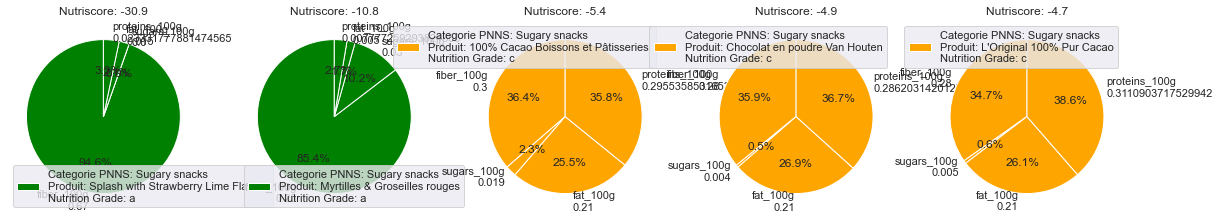

In [239]:
import ipywidgets as widgets
from IPython.display import display

# Créer le menu déroulant pour choisir le produit
product_dropdown = widgets.Dropdown(
    options=list(nutri_app_scaled['product_name']),
    description='Produit:'
)

# Fonction pour mettre à jour les prédictions et afficher le diagramme circulaire pour le produit sélectionné
def update_product(product_name):
    # Trouver la catégorie PNNS du produit sélectionné
    product_pnns_group1 = nutri_app_scaled.loc[nutri_app_scaled['product_name'] == product_name, 'pnns_group1'].values[0]
    # Sélectionner tous les produits de la même catégorie PNNS
    same_category_products = nutri_app_scaled.loc[nutri_app_scaled['pnns_group1'] == product_pnns_group1]
    # Calculer les prédictions du nutriscore pour tous les produits de la même catégorie
    same_category_products_predictions = same_category_products[features].values * reg.coef_
    same_category_products_predictions = same_category_products_predictions.sum(axis=1)
    same_category_products['predictions'] = same_category_products_predictions
    # Sélectionner les 5 produits ayant les nutriscores les plus bas prédits
    top_products = same_category_products.nsmallest(5, 'predictions')
    # Afficher les diagrammes circulaires pour les 5 produits
    fig, axs = plt.subplots(1, 5, figsize=(20, 5))
    for i, product in enumerate(top_products.iterrows()):
        product_name = product[1]['product_name']
        nutrition_grade_fr = product[1]['nutrition_grade_fr']
        product_composition = product[1][features]
        # Diviser chaque feature par la somme de tous les features pour obtenir la proportion de chaque feature dans le produit sélectionné
        product_composition = product_composition / product_composition.sum()
        predicted_nutriscore = product[1]['predictions']
        # Définir une couleur en fonction du nutrition grade
        if nutrition_grade_fr == 'a':
            color = 'green'
        elif nutrition_grade_fr == 'b':
            color = 'yellowgreen'
        elif nutrition_grade_fr == 'c':
            color = 'orange'
        elif nutrition_grade_fr == 'd':
            color = 'orangered'
        elif nutrition_grade_fr == 'e':
            color = 'red'           
        else:
            color = 'red'
        # Afficher le diagramme circulaire
        axs[i].pie(product_composition, labels=[f"{feature}\n{product[1][feature]}" for feature in features], autopct='%1.1f%%', startangle=90, colors=[color for _ in features])
        axs[i].legend(labels=[f"Categorie PNNS: {product_pnns_group1}\nProduit: {product_name}\nNutrition Grade: {nutrition_grade_fr}"])
        axs[i].set_title(f"Nutriscore: {predicted_nutriscore:.1f}")

# Appeler la fonction update_product avec la valeur actuelle du menu déroulant
def dropdown_eventhandler(change):
    update_product(change.new)

# Connecter le menu déroulant à la fonction dropdown_eventhandler
product_dropdown.observe(dropdown_eventhandler, names='value')

# Afficher le menu déroulant et le diagramme circulaire pour le premier produit dans le DataFrame
display(product_dropdown)
update_product(nutri_app_scaled['product_name'].iloc[0])

   


In [255]:
nutri_app_scaled[['product_name','nutriscore_num','nutrition_grade_fr','pnns_group1']].iloc[60]

product_name          Nems de Porc et sauce Nuoc Mâm
nutriscore_num                                     4
nutrition_grade_fr                                 d
pnns_group1                          Composite foods
Name: 93, dtype: object

/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_22716/979513420.py:19: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  same_category_products['predictions'] = same_category_products_predictions


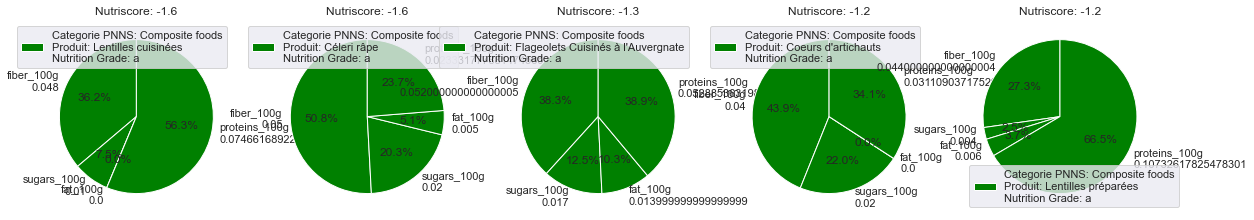

In [249]:
update_product(nutri_app_scaled['product_name'].iloc[60])

# Conclusion faisabilité app

## Limites :

• Le jeu de données est très limité en termes de quantité et d'informations fournies. L'utilisation de l'ANOVA et de l'ACP ne sera pas suffisante pour effectuer une imputation efficace des valeurs manquantes et pour estimer les données manquantes avec précision.

• Pour utiliser les tests paramétriques, il est important que les données suivent une distribution normale. Si les données ne suivent pas une distribution normale, les tests paramétriques peuvent donner des résultats erronés. Dans ce cas, il est souvent nécessaire d'utiliser des tests non paramétriques, qui ne supposent pas une distribution spécifique des données. Les tests non paramétriques incluent, par exemple, le test de Wilcoxon, le test de Mann-Whitney, le test de Kruskal-Wallis, etc.

• En utilisant au moins 10 caractéristiques, nous pouvons observer une variance cumulée d'environ 90% dans l'ACP. À partir de cette observation, nous pouvons en conclure que la création de variables synthétiques ciblées ne serait pas la meilleure option pour une représentation optimale.

## Justifier l'app :

<strong>Faisabilité :</strong> <br><br>
justifier avec résultat ACP et Anova l'utilité de l'app<br><br>
• ACP, ANOVA >
• Kruskal wallis ✅

>intéret de l'app : avoir entrainé modele sur dataset imputé pour utiliser modèle sur dataset initial et deviner nutrition grade

>% de NaN au-dessus de 80% lors du nettoyage
>permet de combler ce dataset

>31% de Nutrition grade manquant qu'on peut remplir grace à l'application



In [ ]:
justifier en montrant que les nutriments fibres etc sont présents à%% dans le dataset

Solution : utiliser la régression linéaire pour étudier l'impact des composants d'un produit sur son nutriscore. 
Utiliser des méthodes de clustering pour regrouper les produits en catégories men fonction de leur composition en nutriments et étudier le nutriscore de chaque groupe.

La faisabilité d'une application utilisant l'ACP (Analyse en Composantes Principales), l'ANOVA, le test de Kruskal-Wallis et une régression linéaire pour recommander des produits en fonction des nutriments et leur impact sur le nutriscore dépend de plusieurs facteurs, tels que la qualité des données, la quantité de données disponibles et la pertinence des hypothèses de départ.

Tout d'abord, il est important d'avoir des données de qualité et en quantité suffisante pour réaliser l'ACP et l'ANOVA. L'ACP est une méthode d'analyse de données qui vise à réduire la dimensionnalité des données, en identifiant les variables les plus importantes qui expliquent la variance totale. L'ANOVA, quant à elle, est un test statistique utilisé pour déterminer si les moyennes de plusieurs groupes sont significativement différentes les unes des autres. Pour cela, il est nécessaire d'avoir des données quantitatives et des groupes bien définis.

Ensuite, le test de Kruskal-Wallis est un test non paramétrique qui peut être utilisé si les hypothèses de normalité et d'homoscédasticité ne sont pas vérifiées. Il est important de vérifier ces hypothèses avant d'utiliser l'ANOVA, car si elles ne sont pas vérifiées, les résultats de l'ANOVA peuvent être erronés.

Enfin, la régression linéaire peut être utilisée pour évaluer la relation entre les nutriments et le nutriscore, ainsi que pour prédire le nutriscore en fonction des nutriments. Il est important de noter que la régression linéaire suppose que la relation entre les variables est linéaire, ce qui peut ne pas être le cas dans certaines situations.

Dans l'ensemble, si les hypothèses de départ sont vérifiées et que les données sont de qualité et en quantité suffisante, l'utilisation de l'ACP, de l'ANOVA, du test de Kruskal-Wallis et de la régression linéaire peut être une approche pertinente pour recommander des produits en fonction des nutriments et de leur impact sur le nutriscore. Cependant, il est important de rappeler que ces analyses doivent être interprétées avec prudence et doivent être accompagnées d'une évaluation critique des résultats obtenus.

In [ ]:
xtrain test r2 sur la regression lineaire par exemple

Dropdown(description='Produit :', options=('Extra Fondant', 'Jellied Cranberry Sauce', 'Brooks Street Bakery, …

/var/folders/t1/qqkjycjj3s1blsc91ykwpg7h0000gn/T/ipykernel_22716/1796448390.py:26: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  same_category_products['predictions'] = same_category_products_predictions


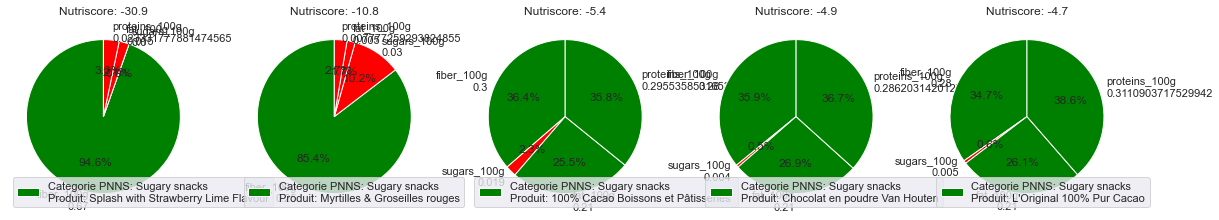

In [251]:
import tkinter as tk
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display

#Créer la fenêtre principale Tkinter
root = tk.Tk()

#Créer le menu déroulant pour choisir le produit
product_dropdown = widgets.Dropdown(options=nutri_app_scaled['product_name'].unique(), value=nutri_app_scaled['product_name'].iloc[0], description='Produit :')
# Créer une fonction pour mettre à jour le graphique en fonction du produit sélectionné
def dropdown_eventhandler(change):
    product_name = change.new
    update_product(product_name)

# Fonction pour mettre à jour les prédictions et afficher le diagramme circulaire pour le produit sélectionné
def update_product(product_name):

    # Trouver la catégorie PNNS du produit sélectionné
    product_pnns_group1 = nutri_app_scaled.loc[nutri_app_scaled['product_name'] == product_name, 'pnns_group1'].values[0]
    # Sélectionner tous les produits de la même catégorie PNNS
    same_category_products = nutri_app_scaled.loc[nutri_app_scaled['pnns_group1'] == product_pnns_group1]
    # Calculer les prédictions du nutriscore pour tous les produits de la même catégorie
    same_category_products_predictions = same_category_products[features].values * reg.coef_
    same_category_products_predictions = same_category_products_predictions.sum(axis=1)
    same_category_products['predictions'] = same_category_products_predictions
    # Sélectionner les 5 produits ayant les nutriscores les plus bas prédits
    top_products = same_category_products.nsmallest(5, 'predictions')
    # Afficher les diagrammes circulaires pour les 5 produits
    fig, axs = plt.subplots(1, 5, figsize=(20, 5))
    for i, product in enumerate(top_products.iterrows()):
        product_name = product[1]['product_name']
        product_composition = product[1][features]
        # Diviser chaque feature par la somme de tous les features pour obtenir la proportion de chaque feature dans le produit sélectionné
        product_composition = product_composition / product_composition.sum()
        predicted_nutriscore = product[1]['predictions']
        # Définir une couleur pour chaque feature en fonction de sa valeur
        colors = []
        for j, feature in enumerate(features):
            if product[1][feature] > nutri_app_scaled[feature].mean():
                colors.append('green')
            else:
                colors.append('red')
        # Afficher le diagramme circulaire
        axs[i].pie(product_composition, labels=[f"{feature}\n{product[1][feature]}" for feature in features], autopct='%1.1f%%', startangle=90, colors=colors)
        axs[i].legend(labels=[f"Categorie PNNS: {product_pnns_group1}\nProduit: {product_name}"])
        axs[i].set_title(f"Nutriscore: {predicted_nutriscore:.1f}")
    plt.show()

# Lier le menu déroulant à l'observateur dropdown_eventhandler
product_dropdown.observe(dropdown_eventhandler)

# Afficher le menu déroulant pour choisir le produit
display(product_dropdown)

# Afficher le diagramme circulaire pour le premier produit dans le DataFrame
update_product(nutri_app_scaled['product_name'].iloc[0])


In [254]:
import pandas as pd
from tkinter import *

df = nutri_app.copy()
df.drop_duplicates(subset = "product_name", keep = 'first', inplace = True)

#definir les colonnes à utiliser
columns = ['energy_100g', 'sugars_100g','fat_100g','proteins_100g', 'nutrition_grade_fr', 'pnns_group1', 'product_name']

#popup avec input utilisateur
window = Tk() 
window.title("Recommandation Nutritionnelle")

#créer le menu déroulant
def show_recommendations():
    #on recupère le nom du produit sélectionné
    selected_product = product_list.get()
    #on trie les produits par nutriscore
    df_sorted = df.sort_values(by = 'nutrition_grade_fr')
    #on selectionne le produit choisi
    optimal_product = df_sorted[df_sorted['product_name'] == selected_product].iloc[0]
    #on selectionne les 5 produits avec un nutriscore optimal
    recommendations = df_sorted[df_sorted['pnns_group1'] == optimal_product['pnns_group1']].iloc[:5]
    #on affiche les informations nutritionnelles des produits recommandés
    print(recommendations[columns])
    

product_list = StringVar(window)
product_list.set("Selectionner un produit")
drop_down = OptionMenu(window, product_list, *df['product_name'])
drop_down.pack()

#créer le bouton
recommendation_button = Button(window, text = "Afficher les recommandations", command = show_recommendations)
recommendation_button.pack()

#lancer la fenêtre
window.mainloop()


      energy_100g  sugars_100g  fat_100g  proteins_100g nutrition_grade_fr    pnns_group1                                       product_name
1177       1665.0          4.9    0.0179            6.8                  a  Sugary snacks                        Tartines Gourmandes Souchet
2985       1715.0          1.4    0.1400            6.8                  a  Sugary snacks  Biscuits Petit-Déjeuner Céréales Complètes San...
5596        769.0          0.0    0.0150            1.5                  a  Sugary snacks                Splash with Strawberry Lime Flavour
5195        354.0         10.0    0.0080            0.1                  a  Sugary snacks                            Postre cremoso de arroz
5741        336.0          3.0    0.0050            0.5                  a  Sugary snacks                      Myrtilles & Groseilles rouges
      energy_100g  sugars_100g  fat_100g  proteins_100g nutrition_grade_fr    pnns_group1                                       product_name
1177       16